<a href="https://colab.research.google.com/github/Bovi-analytics/Mallikarjuna-et-al-2026/blob/main/LOS_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


# Install R and connect to be able to use R magic cells

In [2]:
!pip uninstall rpy2 -y
!pip install rpy2==3.5.1

Found existing installation: rpy2 3.5.17
Uninstalling rpy2-3.5.17:
  Successfully uninstalled rpy2-3.5.17
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 201.7/201.7 kB 5.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for rpy2: filename=rpy2-3.5.1-cp313-cp313-linux_x86_64.whl size=317247 sha256=6f5ccba9219c1720acf85121b2291855e5343cb7ba15bb12b1e5fc287bd9c5ac
  Stored in directory: /root/.cache/pip/wheels/7e/3a/c3/727f9483ff112acd9f3bdb5e88d902d0f539c1751ce4a24f01
Successfully built rpy2


In [3]:
%load_ext rpy2.ipython

From now on you can use the %%R in front of your code to use R in Colab.

*   Make a link to the folder where to store the R libraries.
*   Next a list of libraries is created which are needed for this project.
*   R libraries will be installed when missing. This can take some time initially but becomes quicker after initial install.

In [4]:
%%R

.libPaths("/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/R-lib/")

#Packages
packages <- c(
  "readr","ggplot2","dplyr","tidyr","openxlsx",
  "data.table","lubridate","skimr","fuzzyjoin",
  "readxl","knitr","stringr","broom","glmnet",
  "caret","pROC","brglm2","rpart","rpart.plot",
  "logistf", "precrec","partykit",      # CTree figure
  "mice",          # multiple imputation (replaces na.omit)
  "lme4",          # birth weight mixed model
  "lmerTest",      # p-values for lme4
  "dcurves",       # decision curve analysis
  "rms",           # calibration (val.prob) + restricted cubic splines
  "pmsampsize",    # EPV / sample size adequacy check
  "ggbeeswarm",    # nicer jitter for any dot plots
  "scales"         # axis formatting in ggplot2
)

#Install only missing packages
installed_in_custom_lib <- installed.packages(lib = .libPaths()[1])[, "Package"]
new_packages <- packages[!(packages %in% installed_in_custom_lib)]

if(length(new_packages) > 0){
  install.packages(new_packages, repos = "https://cloud.r-project.org", lib = .libPaths()[1], dependencies = TRUE) # Specify lib for installation
}

#Load all packages
invisible(lapply(packages, library, character.only = TRUE))

cat("ALL PACKAGES INSTALLED + LOADED\n")

Attaching package: ‘dplyr’



    filter, lag



    intersect, setdiff, setequal, union



Attaching package: ‘data.table’



    between, first, last



    %notin%


Attaching package: ‘lubridate’



    hour, isoweek, isoyear, mday, minute, month, quarter, second, wday,
    week, yday, year



    date, intersect, setdiff, union



Attaching package: ‘Matrix’



    expand, pack, unpack





Attaching package: ‘pROC’



    cov, smooth, var


  method               from    
  as.character.formula openxlsx

Attaching package: ‘precrec’



    auc





Attaching package: ‘mice’



    filter



    cbind, rbind


Attaching package: ‘lme4’



    toenail


Attaching package: ‘lmerTest’



    lmer



    step



Attaching package: ‘Hmisc’



    src, summarize



    format.pval, units


Attaching package: ‘scales’



    col_factor




ALL PACKAGES INSTALLED + LOADED


In [5]:
%%R
# Figure & Output Setup
base_drive <- '/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester'
FigDir     <- file.path(base_drive, "Figures")
TabDir     <- file.path(base_drive, "Tables")
dir.create(FigDir, showWarnings = FALSE, recursive = TRUE)
dir.create(TabDir, showWarnings = FALSE, recursive = TRUE)

# Colours
COL_BLUE  <- "#2171b5"
COL_RED   <- "#cb181d"
COL_GREEN <- "#238b45"
COL_GREY  <- "#636363"

# Convert snake_case column names to readable figure labels
CleanLabel <- function(x) {
  x %>%
    stringr::str_replace_all("_", " ") %>%
    stringr::str_to_title()
}

# ggplot2 theme
theme_los <- function() {
  ggplot2::theme_classic(base_size = 13) +
  ggplot2::theme(
    plot.title    = ggplot2::element_text(face = "bold", size = 14),
    plot.subtitle = ggplot2::element_text(colour = COL_GREY, size = 11),
    axis.title    = ggplot2::element_text(face = "bold"),
    legend.position = "bottom",
    strip.background = ggplot2::element_blank(),
    strip.text    = ggplot2::element_text(face = "bold")
  )
}
LABEL_MAP <- c(
  "stripping_time"                                  = "Denudation Duration (sec)",
  "in_vitro_maturation_time"                        = "IVM Duration (min)",
  "in_vitro_fertilisation_time"                     = "IVF Duration (min)",
  "coasting_duration"                               = "Coasting Duration (min)",
  "dam_age_at_opu_months"                           = "Donor Age at OPU (months)",
  "recipient_age_years"                             = "Recipient Age (years)",
  "embryos_per_oocyte"                              = "Embryos per Oocyte",
  "cleavage_per_oocyte"                             = "Cleavage per Oocyte",
  "embryos_per_transfer"                            = "Embryos per Transfer",
  "prop_good_quality"                               = "Proportion Good Quality",
  "follicle_ratio"                                  = "Follicle Ratio (large/small)",
  "cumulus_ratio"                                   = "Cumulus Ratio",
  "heparin_concentration_in_fertilisation_droplets" = "Heparin Concentration (µg/mL)",
  "sire_birth_year"                                 = "Sire Birth Year",
  "embryo_age"                                      = "Embryo Age (days)",
  "recipient_cycle_date"                            = "Recipient Cycle Day",
  "sync_category"                                   = "Synchrony Category",
  "embryo_grade"                                    = "Embryo Grade"
)

CleanLabel <- function(x) {
  dplyr::if_else(x %in% names(LABEL_MAP), LABEL_MAP[x],
    stringr::str_to_title(stringr::str_replace_all(x, "_", " ")))
}
# Save PDF + PNG at 300 DPI — PascalCase filename, no extension needed
SaveFig <- function(plot, name, width = 10, height = 7) {
  ggplot2::ggsave(file.path(FigDir, paste0(name, ".pdf")),
                  plot, width = width, height = height)
  ggplot2::ggsave(file.path(FigDir, paste0(name, ".png")),
                  plot, width = width, height = height, dpi = 300)
  message("Saved: ", name, ".pdf / .png")
}

cat("Figure setup complete. FigDir:", FigDir, "\n")
cat("TabDir:", TabDir, "\n")

Figure setup complete. FigDir: /content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/Figures 
TabDir: /content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/Tables 


# Import the data



## Calf-donor IDs


In [6]:
%%R
# Load the data for calf-donor IDs
df_raw_calf_donor_IDs <- readr::read_csv(
    file = '/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/raw_data/calfid_rid.CSV')
glimpse(df_raw_calf_donor_IDs)

New names:
• `` -> `...5`
Rows: 6223 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): ID, BDAT, RDAM
dbl (1): DID
lgl (1): ...5

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 6,223
Columns: 5
$ ID   <chr> "895", "1111", "1220", "1292", "1365", "1383", "1387", "1389", "1…
$ DID  <dbl> 0, 0, 0, 23719, 23719, 24222, 6288, 24548, 24090, 24090, 24135, 2…
$ BDAT <chr> "04/10/18", "10/21/19", "07/30/23", "06/06/23", "10/15/23", "10/2…
$ RDAM <chr> "0", "0", "0", "024057", "024461", "024446", "024476", "023423", …
$ ...5 <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, N…


In [7]:
%%R
# Fix formatting
df_calf_damIDs <- df_raw_calf_donor_IDs %>%
  dplyr::rename(
      calf_ID = 1,
      recipient_ID = RDAM,
      recipient_calving_date = BDAT,
      dam_ID = DID) %>%
    dplyr::mutate(
        recipient_calving_date = as.Date(recipient_calving_date, format = "%m/%d/%y"),
        calf_ID = as.character(calf_ID),
        recipient_ID = as.character(recipient_ID),
         # REMOVE leading zeros
        calf_ID = sub("^0+", "", calf_ID),
        recipient_ID = sub("^0+", "", recipient_ID)
        )
    df_calf_damIDs <- df_calf_damIDs %>%
  dplyr::select(calf_ID, recipient_ID, recipient_calving_date, dam_ID)
glimpse(df_calf_damIDs)

Rows: 6,223
Columns: 4
$ calf_ID                <chr> "895", "1111", "1220", "1292", "1365", "1383", …
$ recipient_ID           <chr> "", "", "", "24057", "24461", "24446", "24476",…
$ recipient_calving_date <date> 2018-04-10, 2019-10-21, 2023-07-30, 2023-06-06…
$ dam_ID                 <dbl> 0, 0, 0, 23719, 23719, 24222, 6288, 24548, 2409…


## Navel treatment data

In [8]:
%%R
#Load dataset
df_raw_navel_treatements <- readr::read_csv(
    file = '/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/farm_navel_treatments.csv')
glimpse(df_raw_navel_treatements)

Rows: 116 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): Event, Date, Remark
dbl (2): ID, DIM
lgl (2): Protocols, Technician

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 116
Columns: 7
$ ID         <dbl> 1501, 1506, 1508, 1510, 1537, 1540, 1564, 1565, 1565, 1565,…
$ Event      <chr> "NAVEL", "NAVEL", "NAVEL", "NAVEL", "NAVEL", "NAVEL", "NAVE…
$ DIM        <dbl> 13, 7, 6, 5, 16, 14, 24, 0, 0, 7, 7, 19, 20, 18, 14, 316, 1…
$ Date       <chr> "8/15/2024", "8/15/2024", "8/15/2024", "8/15/2024", "10/1/2…
$ Remark     <chr> "PENICILI", "PENICILI", "PENICILI", "PENICILI", "PENICILI",…
$ Protocols  <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ Technician <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…


In [9]:
%%R
#Format dataset
df_navel_treatments <- df_raw_navel_treatements %>%
  dplyr::rename(
      calf_ID = ID, #Change all column names
      navel_treatment_date = Date,
      navel_treatment_type = Remark,
      calf_age = DIM
      ) %>%
    dplyr::mutate(
        navel_treatment_date = as.Date(navel_treatment_date, format = "%m/%d/%Y"),
        navel_indicator = TRUE,
        calf_ID = as.character(calf_ID), #Fix datetimes and column formatting
        recipient_calving_date= navel_treatment_date - calf_age
    ) %>%
    dplyr::select(calf_ID,navel_indicator,recipient_calving_date)%>%
    dplyr::distinct()
    #Remove duplicates
glimpse(df_navel_treatments)

Rows: 81
Columns: 3
$ calf_ID                <chr> "1501", "1506", "1508", "1510", "1537", "1540",…
$ navel_indicator        <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ recipient_calving_date <date> 2024-08-02, 2024-08-08, 2024-08-09, 2024-08-10…


Check if navel treatments are made unique so always 1 calf is selected

## Recipient records

In [10]:
%%R
#Load the data for recipient birthdates
df_raw_recipient_birthdates <- readr::read_csv(
    file = '/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/raw_data/farm_recipient_birthdates.csv'
    )
glimpse(df_raw_recipient_birthdates)


Rows: 4173 Columns: 2
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, BDAT

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 4,173
Columns: 2
$ ID   <chr> "1220", "1467", "1477", "1489", "1492", "1498", "1506", "1510", "…
$ BDAT <chr> "7/30/2023", "5/11/2024", "5/20/2024", "5/26/2024", "5/29/2024", …


In [11]:
%%R
#Rename and format cols correctly for birthdates
df_recipient_birthdates <- df_raw_recipient_birthdates %>%
  dplyr::rename( #Rename cols so that we can use recip ID as keys
      recipient_ID = ID,
      recipient_birthdate = BDAT
      ) %>%
  dplyr::mutate( #Reformat birthdate column to date
      recipient_birthdate = as.Date(recipient_birthdate, format = "%m/%d/%Y")
  )
  glimpse(df_recipient_birthdates)

Rows: 4,173
Columns: 2
$ recipient_ID        <chr> "1220", "1467", "1477", "1489", "1492", "1498", "1…
$ recipient_birthdate <date> 2023-07-30, 2024-05-11, 2024-05-20, 2024-05-26, 2…


In [12]:
%%R #Load in recipient dam records
#Change col types so data is formatted correctly
df_raw_recipient_records <- readr::read_csv(
    file = '/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/raw_data/farm_calving_records_recipients.csv',
    col_types = readr::cols(
          ID = readr::col_character(),
          Date = readr::col_character(),
          Remark = readr::col_character(),
          DIM = readr::col_character()
          )
      )
glimpse(df_raw_recipient_records)

Rows: 6,685
Columns: 7
$ ID         <chr> NA, "874", "895", "895", "1111", "1111", "1665", "1665", "1…
$ Event      <chr> NA, "FRESH", "FRESH", "FRESH", "FRESH", "FRESH", "FRESH", "…
$ DIM        <chr> NA, "0", "0", "0", "0", "0", "0", "0", "0", "0", "0", "0", …
$ Date       <chr> NA, "3/1/2023", "2/14/2023", "4/11/2024", "10/26/2023", "8/…
$ Remark     <chr> NA, "F", "MANGUS", "FANGUS", "F", "TRIPLETS", "F", "M", "F-…
$ Protocols  <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ Technician <lgl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…


1.Farm_calving_records_recipients could be used to confirm the embryos
(F/M) are embryos

2.ID here is recipient ID and not calf ID

In [13]:
%%R
 #Rename cols so that we can use them as keys
 #Select relevant columns - we only need id, calving date, calf gender
 #Format dates correctly
df_recipient_records <- df_raw_recipient_records %>%
  dplyr::rename(
      recipient_ID = ID,
      recipient_calving_date = Date,
      calf_gender_remark = Remark) %>%
  dplyr::select(
      recipient_ID,
      recipient_calving_date,
      calf_gender_remark) %>%
  dplyr::mutate(
      recipient_calving_date = as.Date(recipient_calving_date, format = "%m/%d/%Y")
      )
glimpse(df_recipient_records)

Rows: 6,685
Columns: 3
$ recipient_ID           <chr> NA, "874", "895", "895", "1111", "1111", "1665"…
$ recipient_calving_date <date> NA, 2023-03-01, 2023-02-14, 2024-04-11, 2023-1…
$ calf_gender_remark     <chr> NA, "F", "MANGUS", "FANGUS", "F", "TRIPLETS", "…


## Embryo transfer

You need


*   Read each sheet seperately
*   Apply naming convention to each sheet
*   Add identifier to each dataframe reflecting sheet where it comes from
*   Select exactly the same columns in each sheet
*   Union all into 1 dataframe



In [14]:
%%R

# For-loop to read each sheet of the excel file into a seperate data frame (code from Stack Overflow)
embryos_file_path <- "/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/raw_data/farm_frozen_embryo_transfers2017.xlsx"
embryos_sheets <- getSheetNames(embryos_file_path)
for (sheet_name in embryos_sheets) {
  assign(sheet_name, read.xlsx(embryos_file_path, sheet = sheet_name))
}

In [15]:
%%R
# Check the name of the sheets
embryos_sheets

#Check that each sheet have been converted to df
class(`Boviteq`)
class(`OakwoodSemex`) # Backticks to prevent space from creating an error
class(`TransOva`)
class(`OakwoodTransfers`)


[1] "data.frame"


In [16]:
%%R
# Change df names to relevant naming convention
boviteq <- Boviteq
oakwood_semex <- `OakwoodSemex`
transova <- TransOva
oakwood_transfers <- `OakwoodTransfers`

In [17]:
#Rename the columns
%%R
boviteq_renamed_select <- Boviteq %>%
  dplyr::rename(
      recipient_ID = Recip,
      recipient_bred_date = `Bred.Date`,
      embryo_transfer_date = `Trans.Date`,
      recipient_heat_date = `Heat.Date`,
      recipient_heat_time = `Heat.Time`,
      transfer_day_of_week = `Transfer.Date`,
      recipient_cycle_day = `Recip.Day`,
      sire_ID = Sire,
      donor_ID = Donor,
      embryo_age = Stage,
      embryo_grade = Grade,
      preg_open_status = `Preg/Open`,
      preg_open_binary = `1.=.Preg`,
      calf_GTPI = GTPI) %>%
  dplyr::select(
      recipient_ID,
      recipient_bred_date,
      embryo_transfer_date,
      recipient_heat_date,
      recipient_heat_time,
      recipient_cycle_day,
      sire_ID,
      transfer_day_of_week,
      donor_ID,
      embryo_age,
      embryo_grade,
      preg_open_status,
      preg_open_binary) %>%
  dplyr::mutate( #Change to correct data types and reformat dates
      recipient_ID = as.character(recipient_ID),
      sire_ID = as.factor(sire_ID),
      donor_ID = as.factor(donor_ID),
      embryo_age = as.factor(embryo_age),
      embryo_grade = as.factor(embryo_grade),
      embryo_transfer_date = as.Date(as.numeric(embryo_transfer_date), origin = "1899-12-30"),
      recipient_bred_date = as.Date(as.numeric(recipient_bred_date), origin = "1899-12-30"),
      recipient_heat_time = as.numeric(recipient_heat_time),
      recipient_cycle_day = as.numeric(recipient_cycle_day),
      preg_open_binary = as.numeric(preg_open_binary),
      lab = "boviteq"           )
  # We cannot include calf GTPI because it's not included in all of the datasets.
  glimpse(boviteq_renamed_select)
  colnames(transova)

Rows: 7,781
Columns: 14
$ recipient_ID         <chr> NA, "19275", "19271", "19261", "19232", "19202", …
$ recipient_bred_date  <date> NA, 2018-09-04, 2018-08-28, 2018-08-28, 2018-08-…
$ embryo_transfer_date <date> NA, 2018-09-11, 2018-09-04, 2018-09-04, 2018-09-…
$ recipient_heat_date  <chr> NA, "MON", "MON", "MON", "FRI", "MON", "MON", "TH…
$ recipient_heat_time  <dbl> NA, 0.25000000, 0.33333333, 0.83333333, 0.0833333…
$ recipient_cycle_day  <dbl> NA, 8.0, 8.0, 7.5, 8.0, 8.0, 8.0, 8.0, 7.0, 7.5, …
$ sire_ID              <fct> NA, EINSTEIN, EINSTEIN, EINSTEIN, EINSTEIN, EINST…
$ transfer_day_of_week <chr> NA, "TUES", "TUES", "TUES", "FRI", "TUES", "TUES"…
$ donor_ID             <fct> NA, 18382/18596, 18382/18596, 18382/18596, 18382/…
$ embryo_age           <fct> NA, 4, 5, 5, 4, 4, 4, 5, 5, 5, 4, 7, 8, 5, 7, 7, …
$ embryo_grade         <fct> NA, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, …
$ preg_open_status     <chr> NA, "PREG", "OPEN", "PREG", "OPEN", "PREG", "PREG…
$ preg_open_bina

In [18]:
#Repeat for the other dfs
%%R
oakwood_semex_renamed_select <- oakwood_semex %>%
  dplyr::rename(
      recipient_ID = Recip,
      recipient_bred_date = `Bred.Date`,
      embryo_transfer_date = `Trans.Date`,
      recipient_heat_date = `Heat.Date`,
      recipient_heat_time = `Heat.Time`,
      transfer_day_of_week = `Transfer.Date`,
      recipient_cycle_day = `Recip.Day`,
      sire_ID = Sire,
      donor_ID = Donor,
      embryo_age = Stage,
      embryo_grade = Grade,
      preg_open_status = `Preg/Open`,
      preg_open_binary = `1.=.Preg`) %>%
  dplyr::select(
      recipient_ID,
      recipient_bred_date,
      embryo_transfer_date,
      recipient_heat_date,
      recipient_heat_time,
      recipient_cycle_day,
      sire_ID,
      transfer_day_of_week,
      donor_ID,
      embryo_age,
      embryo_grade,
      preg_open_status,
      preg_open_binary) %>%
  dplyr::mutate( #Change to correct data types and reformat dates
      recipient_ID = as.character(recipient_ID),
      sire_ID = as.factor(sire_ID),
      donor_ID = as.factor(donor_ID),
      embryo_age = as.factor(embryo_age),
      embryo_grade = as.factor(embryo_grade),
      embryo_transfer_date = as.Date(as.numeric(embryo_transfer_date), origin = "1899-12-30"),
      recipient_bred_date = as.Date(as.numeric(recipient_bred_date), origin = "1899-12-30"),
      recipient_heat_time = as.numeric(recipient_heat_time),
      lab = "oakwood_semex"
                 )
  glimpse(oakwood_semex_renamed_select)
  colnames(oakwood_transfers)

Rows: 322
Columns: 14
$ recipient_ID         <chr> "5261", "5276", "5275", "5263", "5292", "5293", "…
$ recipient_bred_date  <date> 2021-07-23, 2021-07-23, 2021-07-27, 2021-07-28, …
$ embryo_transfer_date <date> 2021-07-31, 2021-07-31, 2021-08-04, 2021-08-05, …
$ recipient_heat_date  <chr> "Fri", "Fri", "Tues", "Wed", "Wed", "Sun", "Wed",…
$ recipient_heat_time  <dbl> 0.25000000, 0.25000000, 0.58333333, 0.91666667, 0…
$ recipient_cycle_day  <dbl> 8.5, 8.5, 8.0, 7.5, 8.0, 8.0, 8.0, 8.0, 7.5, 7.0,…
$ sire_ID              <fct> AltaPlinko, Horoscope, RangerRed, Wheelhouse, Alt…
$ transfer_day_of_week <chr> "Sat", "Sat", "Wed", "Thur", "Thur", "Mon", "Thur…
$ donor_ID             <fct> Packers, 82940.0, 82954.0, PomPom, PomPom, Limitl…
$ embryo_age           <fct> 7, 7, 7, 6, 7, 7, 7, 6, 7, 6, 6, 7, 6, 6, 6, 6, 6…
$ embryo_grade         <fct> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1…
$ preg_open_status     <chr> "OPEN", "OPEN", "OPEN", "PREG", "OPEN", "OPEN", "…
$ preg_open_binary

In [19]:
%%R
colnames(oakwood_transfers)[1] <- "recipient_ID"
oakwood_transfers_renamed_selected <- oakwood_transfers %>%
  dplyr::rename(
      recipient_bred_date = `Bred.Date`,
      embryo_transfer_date = `Trans.Date`,
      recipient_heat_date = `Heat.Date`,
      recipient_heat_time = `Heat.Time`,
      transfer_day_of_week = `Transfer.Date`,
      recipient_cycle_day = `Recip.Day`,
      sire_ID = Sire,
      donor_ID = Donor,
      embryo_age = Stage,
      embryo_grade = Grade,
      preg_open_status = `Option.1`,
      preg_open_binary = `1.=.Preg`) %>%
  dplyr::select(
      recipient_ID,
       transfer_day_of_week,
      recipient_bred_date,
      embryo_transfer_date,
      recipient_heat_date,
      recipient_heat_time,
      recipient_cycle_day,
      sire_ID,
      donor_ID,
      embryo_age,
      embryo_grade,
      preg_open_status,
      preg_open_binary) %>%
  dplyr::mutate( #Change to correct data types and reformat dates
      recipient_ID = as.character(recipient_ID),
      sire_ID = as.factor(sire_ID),
      donor_ID = as.factor(donor_ID),
      embryo_age = as.factor(embryo_age),
      embryo_grade = as.factor(embryo_grade),
      embryo_transfer_date = as.Date(as.numeric(embryo_transfer_date), origin = "1899-12-30"),
      recipient_bred_date = as.Date(as.numeric(recipient_bred_date), origin = "1899-12-30"),
      recipient_heat_time = as.numeric(recipient_heat_time),
      lab = "oakwood_transfers")

glimpse(oakwood_transfers_renamed_selected)
colnames(oakwood_transfers_renamed_selected)


Rows: 1,301
Columns: 14
$ recipient_ID         <chr> NA, "1221", "1235", "1236", "1251", "1268", "1170…
$ transfer_day_of_week <chr> NA, "MON", "MON", "MON", "MON", "MON", "MON", "MO…
$ recipient_bred_date  <date> NA, 2017-10-30, 2017-10-30, 2017-10-30, 2017-10-…
$ embryo_transfer_date <date> NA, 2017-11-06, 2017-11-06, 2017-11-06, 2017-11-…
$ recipient_heat_date  <chr> NA, "SUN", "SUN", "SUN", "MON", "MON", "SUN", "MO…
$ recipient_heat_time  <dbl> NA, 0.87500000, 0.62500000, 0.95833333, 0.0416666…
$ recipient_cycle_day  <dbl> NA, 7.5, 7.5, 7.5, 7.0, 7.0, 8.0, 7.0, 7.0, 7.0, …
$ sire_ID              <fct> NA, FORTUNE, FORTUNE, FORTUNE, FORTUNE, FORTUNE, …
$ donor_ID             <fct> NA, 1958/17248, 1958/17248, 1958/17248, 1958/1724…
$ embryo_age           <fct> NA, 7, 6, 6, 5, 4, 6, 5, 5, 7, 7, 7, 7, 7, 6, 7, …
$ embryo_grade         <fct> NA, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, …
$ preg_open_status     <chr> NA, "PREG", "PREG", "PREG", "PREG", "PREG", "OPEN…
$ preg_open_bina

In [20]:
%%R
transova_renamed_select <- transova %>%
  dplyr::rename(
      recipient_ID = Recip,
      recipient_bred_date = `Bred.Date`,
      transfer_day_of_week = `Transfer.Date`,
      recipient_heat_date = `Heat.Date`,
      recipient_heat_time = `Heat.Time`, #This dataset is missing the day of the work the trn
      recipient_cycle_day = `Recip.Day`,
      sire_ID = Sire,
      donor_ID = Donor,
      embryo_age = Stage,
      embryo_grade = Grade,
      preg_open_status = `Preg/Open`,
      preg_open_binary = `1.=.Preg`) %>%
  dplyr::select(
      recipient_ID,
      recipient_bred_date,
      transfer_day_of_week,
      recipient_heat_date,
      recipient_heat_time,
      recipient_cycle_day,
      sire_ID,
      donor_ID,
      embryo_age,
      embryo_grade,
      preg_open_status,
      preg_open_binary) %>%
  dplyr::mutate( #Change to correct data types and reformat dates
      recipient_ID = as.character(recipient_ID),
      sire_ID = as.factor(sire_ID),
      donor_ID = as.factor(donor_ID),
      embryo_age = as.factor(embryo_age),
      embryo_grade = as.factor(embryo_grade),
      recipient_bred_date = as.Date(as.numeric(recipient_bred_date), origin = "1899-12-30"),
      embryo_transfer_date = recipient_bred_date %m+% days(7),
      recipient_heat_time = as.numeric(recipient_heat_time),
      lab = "transova"
                 )
  #glimpse(transova_renamed_select)
  glimpse(boviteq_renamed_select)
  #glimpse(oakwood_semex_renamed_select)
  #glimpse(oakwood_transfers_renamed_selected)

Rows: 7,781
Columns: 14
$ recipient_ID         <chr> NA, "19275", "19271", "19261", "19232", "19202", …
$ recipient_bred_date  <date> NA, 2018-09-04, 2018-08-28, 2018-08-28, 2018-08-…
$ embryo_transfer_date <date> NA, 2018-09-11, 2018-09-04, 2018-09-04, 2018-09-…
$ recipient_heat_date  <chr> NA, "MON", "MON", "MON", "FRI", "MON", "MON", "TH…
$ recipient_heat_time  <dbl> NA, 0.25000000, 0.33333333, 0.83333333, 0.0833333…
$ recipient_cycle_day  <dbl> NA, 8.0, 8.0, 7.5, 8.0, 8.0, 8.0, 8.0, 7.0, 7.5, …
$ sire_ID              <fct> NA, EINSTEIN, EINSTEIN, EINSTEIN, EINSTEIN, EINST…
$ transfer_day_of_week <chr> NA, "TUES", "TUES", "TUES", "FRI", "TUES", "TUES"…
$ donor_ID             <fct> NA, 18382/18596, 18382/18596, 18382/18596, 18382/…
$ embryo_age           <fct> NA, 4, 5, 5, 4, 4, 4, 5, 5, 5, 4, 7, 8, 5, 7, 7, …
$ embryo_grade         <fct> NA, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, …
$ preg_open_status     <chr> NA, "PREG", "OPEN", "PREG", "OPEN", "PREG", "PREG…
$ preg_open_bina

In [21]:
%%R
all_embryo_transfers <- boviteq_renamed_select %>%
  dplyr::union(oakwood_semex_renamed_select) %>%
  dplyr::union(oakwood_transfers_renamed_selected) %>%
  dplyr::union(transova_renamed_select)
all_embryo_transfers <- all_embryo_transfers %>%
  dplyr::mutate(
      approx_recipient_calving_date = all_embryo_transfers$embryo_transfer_date %m+% months(9), #Approximate birthdates
      approx_recipient_calving_date_minus_7 = approx_recipient_calving_date %m-% days(7),
      approx_recipient_calving_date_plus_7 = approx_recipient_calving_date %m+% days(7)
  )
  #separate_rows(donor_ID, sep = "/") #do not seperate here as it explodes and causes duplicates during the joins
  #dplyr::filter(preg_open_binary == 1)
glimpse(all_embryo_transfers)


Rows: 9,665
Columns: 17
$ recipient_ID                          <chr> NA, "19275", "19271", "19261", "…
$ recipient_bred_date                   <date> NA, 2018-09-04, 2018-08-28, 201…
$ embryo_transfer_date                  <date> NA, 2018-09-11, 2018-09-04, 201…
$ recipient_heat_date                   <chr> NA, "MON", "MON", "MON", "FRI", …
$ recipient_heat_time                   <dbl> NA, 0.25000000, 0.33333333, 0.83…
$ recipient_cycle_day                   <dbl> NA, 8.0, 8.0, 7.5, 8.0, 8.0, 8.0…
$ sire_ID                               <fct> NA, EINSTEIN, EINSTEIN, EINSTEIN…
$ transfer_day_of_week                  <chr> NA, "TUES", "TUES", "TUES", "FRI…
$ donor_ID                              <fct> NA, 18382/18596, 18382/18596, 18…
$ embryo_age                            <fct> NA, 4, 5, 5, 4, 4, 4, 5, 5, 5, 4…
$ embryo_grade                          <fct> NA, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2…
$ preg_open_status                      <chr> NA, "PREG", "OPEN", "PREG", "OPE…
$ preg_open_bina

In [22]:
%%R
check <- filter(all_embryo_transfers, recipient_ID == "18491")
glimpse(check)

Rows: 2
Columns: 17
$ recipient_ID                          <chr> "18491", "18491"
$ recipient_bred_date                   <date> 2018-02-16, 2018-03-09
$ embryo_transfer_date                  <date> 2018-02-23, 2018-03-16
$ recipient_heat_date                   <chr> "FRI", "FRI"
$ recipient_heat_time                   <dbl> 0.7500000, 0.8333333
$ recipient_cycle_day                   <dbl> 7.0, 6.5
$ sire_ID                               <fct> PINNACLE, TARRINO
$ transfer_day_of_week                  <chr> "FRI", "FRI"
$ donor_ID                              <fct> 17951/17956/18162, 17926/18201/1…
$ embryo_age                            <fct> 4, 5
$ embryo_grade                          <fct> 1, 1
$ preg_open_status                      <chr> "OPEN", "PREG"
$ preg_open_binary                      <dbl> 0, 1
$ lab                                   <chr> "boviteq", "boviteq"
$ approx_recipient_calving_date         <date> 2018-11-23, 2018-12-16
$ approx_recipient_calving_date_minus_7 <d

In [23]:
%%R
glimpse(all_embryo_transfers %>%
dplyr::filter(between(approx_recipient_calving_date,
                 as.Date("2023-01-01"),
                 as.Date("2025-09-04"))))

Rows: 5,723
Columns: 17
$ recipient_ID                          <chr> "23510", "23532", "23412", "2341…
$ recipient_bred_date                   <date> 2022-03-25, 2022-03-25, 2022-03…
$ embryo_transfer_date                  <date> 2022-04-01, 2022-04-01, 2022-04…
$ recipient_heat_date                   <chr> "THURS", "THURS", "SAT", "SAT", …
$ recipient_heat_time                   <dbl> 0.50000000, 0.66666667, 0.083333…
$ recipient_cycle_day                   <dbl> NA, NA, NA, NA, NA, NA, NA, NA, …
$ sire_ID                               <fct> Ascend, Ascend, Jalapeno, Greycu…
$ transfer_day_of_week                  <chr> "FRI", "FRI", "SAT", "SAT", "SAT…
$ donor_ID                              <fct> Lolipop, Pistachio, Limitless, P…
$ embryo_age                            <fct> 7, 7, 7, 5, 5, 7, 6, 6, 6, 6, 6,…
$ embryo_grade                          <fct> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ preg_open_status                      <chr> "OPEN", "PREG", "OPEN", "PREG", …
$ preg_open_bina

In [24]:
%%R
#delete column recipient_cycle_day because we are making a new column to prevent confusion
all_embryo_transfers <- subset(all_embryo_transfers, select = -c(recipient_cycle_day))


In [25]:
%%R
#create column "recipient_cycle_date" using transfer_day_of_week and recipient_heat_date
all_embryo_transfers <- all_embryo_transfers %>%
  dplyr::mutate(
      #convert heat date to uppercase
      recipient_heat_date = trimws(toupper(recipient_heat_date)),
      transfer_day_of_week = trimws(toupper(transfer_day_of_week)),
      recipient_heat_date = dplyr::case_when(
      recipient_heat_date %in% c("THU", "THUR", "THURS") ~ "THURS",
      recipient_heat_date %in% c("TUE", "TUES") ~ "TUES",
      TRUE ~ recipient_heat_date
                                ),
      transfer_day_of_week = dplyr::case_when(
      transfer_day_of_week %in% c("THU", "THUR", "THURS") ~ "THURS",
      transfer_day_of_week %in% c("TUE", "TUES") ~ "TUES",
      TRUE ~ transfer_day_of_week
                                ),
      recipient_cycle_date = case_when(
      recipient_heat_date == transfer_day_of_week ~ 7,

    recipient_heat_date == "MON" & transfer_day_of_week == "SUN"  ~ 6,
    recipient_heat_date %in% c("TUE", "TUES") & transfer_day_of_week == "MON"  ~ 6,
    recipient_heat_date == "WED" & transfer_day_of_week %in% c("TUE", "TUES")  ~ 6,
    recipient_heat_date %in% c("THU", "THUR", "THURS") & transfer_day_of_week == "WED"  ~ 6,
    recipient_heat_date == "FRI" & transfer_day_of_week %in% c("THU", "THUR", "THURS")  ~ 6,
    recipient_heat_date == "SAT" & transfer_day_of_week == "FRI"  ~ 6,
    recipient_heat_date == "SUN" & transfer_day_of_week == "SAT"  ~ 6,
#for day 8
    recipient_heat_date == "MON" & transfer_day_of_week %in% c("TUE", "TUES")  ~ 8,
    recipient_heat_date %in% c("THU", "THUR", "THURS") & transfer_day_of_week == "FRI"  ~ 8,
    recipient_heat_date == "SUN" & transfer_day_of_week == "MON"  ~ 8,
    recipient_heat_date %in% c("TUE", "TUES") & transfer_day_of_week == "WED"  ~ 8,
    recipient_heat_date == "WED" & transfer_day_of_week %in% c("THU", "THUR", "THURS")  ~ 8,
    recipient_heat_date == "FRI" & transfer_day_of_week == "SAT"  ~ 8,
    recipient_heat_date == "SAT" & transfer_day_of_week == "SUN"  ~ 8,
# for day 9
    recipient_heat_date == "MON" & transfer_day_of_week == "WED"  ~ 9,
    recipient_heat_date %in% c("TUE", "TUES") & transfer_day_of_week %in% c("THU", "THUR", "THURS")  ~ 9,
    recipient_heat_date == "WED" & transfer_day_of_week == "FRI"  ~ 9,
    recipient_heat_date %in% c("THU", "THUR", "THURS") & transfer_day_of_week == "SAT"  ~ 9,
    recipient_heat_date == "FRI" & transfer_day_of_week == "SUN"  ~ 9,
    recipient_heat_date == "SAT" & transfer_day_of_week == "MON"  ~ 9,
    recipient_heat_date == "SUN" & transfer_day_of_week %in% c("TUE", "TUES")  ~ 9,
#day 10
    recipient_heat_date == "MON" & transfer_day_of_week %in% c("THU", "THUR", "THURS")  ~ 10,
    recipient_heat_date %in% c("TUE", "TUES") & transfer_day_of_week == "FRI"  ~ 10,
    recipient_heat_date == "WED" & transfer_day_of_week == "SAT"  ~ 10,
    recipient_heat_date %in% c("THU", "THUR", "THURS") & transfer_day_of_week == "SUN"  ~ 10,
    recipient_heat_date == "FRI" & transfer_day_of_week == "MON"  ~ 10,
    recipient_heat_date == "SAT" & transfer_day_of_week %in% c("TUE", "TUES")  ~ 10,
    recipient_heat_date == "SUN" & transfer_day_of_week == "WED"  ~ 10,
      #day 11
    recipient_heat_date == "MON" & transfer_day_of_week == "FRI"  ~ 11,
    recipient_heat_date %in% c("TUE", "TUES") & transfer_day_of_week == "SAT"  ~ 11,
    recipient_heat_date == "WED" & transfer_day_of_week == "SUN"  ~ 11,
    recipient_heat_date %in% c("THU", "THUR", "THURS") & transfer_day_of_week == "MON"  ~ 11,
    recipient_heat_date == "FRI" & transfer_day_of_week %in% c("TUE", "TUES")  ~ 11,
    recipient_heat_date == "SAT" & transfer_day_of_week == "WED"  ~ 11,
    recipient_heat_date == "SUN" & transfer_day_of_week %in% c("THU", "THUR", "THURS")  ~ 11,
      #day 12 can also be day 4 so what should we do??
    recipient_heat_date == "MON" & transfer_day_of_week == "SAT"  ~ 12,
    recipient_heat_date %in% c("TUE", "TUES") & transfer_day_of_week == "SUN"  ~ 12,
    recipient_heat_date == "WED" & transfer_day_of_week == "MON"  ~ 12,
    recipient_heat_date %in% c("THU", "THUR", "THURS") & transfer_day_of_week %in% c("TUE", "TUES")  ~ 12,
    recipient_heat_date == "FRI" & transfer_day_of_week == "WED"  ~ 12,
    recipient_heat_date == "SAT" & transfer_day_of_week %in% c("THU", "THUR", "THURS")  ~ 12,
    recipient_heat_date == "SUN" & transfer_day_of_week == "FRI"  ~ 12,
      is.na(recipient_heat_date) | is.na(transfer_day_of_week) ~ NA_real_,
      TRUE ~ 99
    ))
  glimpse(all_embryo_transfers)

Rows: 9,665
Columns: 17
$ recipient_ID                          <chr> NA, "19275", "19271", "19261", "…
$ recipient_bred_date                   <date> NA, 2018-09-04, 2018-08-28, 201…
$ embryo_transfer_date                  <date> NA, 2018-09-11, 2018-09-04, 201…
$ recipient_heat_date                   <chr> NA, "MON", "MON", "MON", "FRI", …
$ recipient_heat_time                   <dbl> NA, 0.25000000, 0.33333333, 0.83…
$ sire_ID                               <fct> NA, EINSTEIN, EINSTEIN, EINSTEIN…
$ transfer_day_of_week                  <chr> NA, "TUES", "TUES", "TUES", "FRI…
$ donor_ID                              <fct> NA, 18382/18596, 18382/18596, 18…
$ embryo_age                            <fct> NA, 4, 5, 5, 4, 4, 4, 5, 5, 5, 4…
$ embryo_grade                          <fct> NA, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2…
$ preg_open_status                      <chr> NA, "PREG", "OPEN", "PREG", "OPE…
$ preg_open_binary                      <dbl> NA, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1…
$ lab           

In [26]:
%%R
all_embryo_transfers %>%
  dplyr::count(recipient_cycle_date)

  recipient_cycle_date    n
1                    6   52
2                    7 2292
3                    8 7107
4                    9  196
5                   10    4
6                   11    2
7                   12    3
8                   NA    9


In [27]:
%%R
summary(all_embryo_transfers)

    recipient_ID  recipient_bred_date  embryo_transfer_date recipient_heat_date
 Length   :9665   Min.   :2017-04-25   Min.   :2017-05-02   Length   :9665     
 N.unique :6493   1st Qu.:2021-06-02   1st Qu.:2021-06-10   N.unique :   7     
 N.blank  :   0   Median :2023-01-06   Median :2023-01-13   N.blank  :   0     
 Min.nchar:   4   Mean   :2022-07-03   Mean   :2022-07-10   Min.nchar:   3     
 Max.nchar:   5   3rd Qu.:2024-02-11   3rd Qu.:2024-02-18   Max.nchar:   5     
 NAs      :   2   Max.   :2025-02-23   Max.   :2025-03-02   NAs      :   9     
                  NAs    :6            NAs    :3                               
 recipient_heat_time       sire_ID     transfer_day_of_week        donor_ID   
 Min.   :0.0000      Sheepster : 330   Length   :9665       25888 25893: 206  
 1st Qu.:0.1667      Sundance  : 320   N.unique :   7       26094.0    : 173  
 Median :0.4167      Letchworth: 202   N.blank  :   0       26296.0    : 145  
 Mean   :0.4207      Recharge  : 190   Min.n

## Lab summary data

In [28]:
%%R

#Load raw lab summaries
df_raw_lab_summary_ny <- read_excel(
  path = "/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/raw_data/lab_data/aurora_ridge_syracuse_ny_summary.xlsx"
)

df_raw_lab_summary_wi <- read_excel(
  path = "/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/raw_data/lab_data/aurora_ridge_madison_wi_summary.xlsx"
)

#Formatting
clean_lab_names <- function(df) {
  df %>%
    rename_with(tolower) %>%
    rename_with(~ gsub(" ", "_", .x)) %>%
    rename_with(~ gsub("-", "_", .x)) %>%
    rename_with(~ gsub("%", "percent", .x)) %>%
    rename_with(~ gsub(">", "greater_than", .x)) %>%
    rename_with(~ gsub("≥", "greater_than_or_equal_to", .x))
}

#NY lab data
df_lab_summary_ny <- df_raw_lab_summary_ny %>%
  clean_lab_names() %>%
  rename(
    donor_ID               = dam_short_name,
    sire_ID                = sire_a_short_name,
    embryo_collection_date = embryo_lot_date
  ) %>%
  mutate(boviteq_lab_ID = "ny")

#WI lab data
df_lab_summary_wi <- df_raw_lab_summary_wi %>%
  clean_lab_names() %>%
  rename(
    donor_ID               = dam_short_name,
    sire_ID                = sire_a_short_name,
    embryo_collection_date = embryo_lot_date
  ) %>%
  mutate(boviteq_lab_ID = "wi")

#Columns that should split together
split_cols <- c(
  "donor_ID",
  "dam_boviteq_number",
  "dam_starting_state",
  "spo_program",
  "coasting_duration",
  "dam_birth_date",
  "dam_age_at_opu",
  "dam_registration_number",
  "dam_complete_name",
  "dam_breed"
)

#Combine + clean + split
lab_data <- bind_rows(df_lab_summary_ny, df_lab_summary_wi) %>%

  mutate(
    sire_ID = str_remove(sire_ID, "\\s*\\(.*\\)"),
    sire_ID = str_trim(sire_ID),
    sire_ID = toupper(sire_ID),
    donor_number = str_extract(donor_ID, "\\d+"),
    donor_number = as.character(donor_number),

    embryo_collection_date = as.Date(embryo_collection_date)
  ) %>%

  #Replace multiline separators with unique delimiter
  mutate(
    across(
      all_of(split_cols),
      ~ str_replace_all(as.character(.), "\n", "|||")
    )
  ) %>%

  #Split donor-level columns in parallel
  separate_rows(
    all_of(split_cols),
    sep = "\\|\\|\\|"
  ) %>%

  #Clean split columns
  mutate(
    across(
      all_of(split_cols),
      ~ str_trim(.)
    ),
    donor_ID = str_replace_all(donor_ID, "\\.0$", "")
  ) %>%
  #Remove empty donor rows
  filter(
    !is.na(donor_ID),
    donor_ID != ""
  ) %>%

  #Derived variables
  mutate(
    prop_good_quality = good_quality_morulas / number_of_morulas,
    prop_poor_quality = poor_quality_morulas / number_of_morulas
  )

#Check remaining \ issues
n_remaining <- lab_data %>%
  select(all_of(split_cols)) %>%
  filter(if_any(everything(), ~ str_detect(., "\n"))) %>%
  nrow()
cat("\nRows still containing \\n:", n_remaining, "\n")
cat("Total rows after split:", nrow(lab_data), "\n")

glimpse(lab_data)


Rows still containing \n: 0 
Total rows after split: 1390 
Rows: 1,390
Columns: 69
$ opu_date                                        <dttm> 2022-12-06, 2022-12-0…
$ insemination_date                               <dttm> 2022-12-06, 2022-12-0…
$ embryo_lot                                      <chr> "22DE14", "22DE14", "2…
$ embryo_collection_date                          <date> 2022-12-14, 2022-12-1…
$ flush_date                                      <dttm> 2022-12-14, 2022-12-1…
$ laboratory                                      <chr> "Boviteq USA", "Bovite…
$ collection_site                                 <chr> "White Oak Vet Clinic"…
$ dam_boviteq_number                              <chr> "HO24417", "HO24935", …
$ donor_ID                                        <chr> "AHEAD 6348", "GAMEDAY…
$ dam_complete_name                               <chr> "Aurora AHEAD 6348-ET"…
$ dam_registration_number                         <chr> "HO840F3233449771", "H…
$ dam_breed                         

## C Sections

In [29]:
%%R #Load in farm csection data
library(readr)
df_raw_farm_caesarean_sections_recipients <- readr::read_csv(
    file = '/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/raw_data/farm_caesarean_sections_recipients.csv',
    col_types = readr::cols(
        ID = readr::col_character(),
        Date = readr::col_character(),
        Remark = readr::col_character(),
        )
    )

In [30]:
%%R
#Apply naming convention to cols in csection data
df_farm_caesarean_sections_recipients <- df_raw_farm_caesarean_sections_recipients %>%
  dplyr::rename(
    recipient_ID = ID,
    recipient_calving_date = Date,
    caesarean_remark = Remark
  ) %>%
  dplyr::select(
    recipient_ID,
    recipient_calving_date,
    caesarean_remark
  ) %>%
  dplyr::mutate(
    recipient_calving_date = as.Date(recipient_calving_date, format = "%m/%d/%Y"),
    caesarean_indicator = as.factor(TRUE)
  )
glimpse(df_farm_caesarean_sections_recipients)

Rows: 18
Columns: 4
$ recipient_ID           <chr> "23605", "23730", "24138", "24299", "24297", "2…
$ recipient_calving_date <date> 2023-02-01, 2023-04-04, 2023-07-19, 2023-09-25…
$ caesarean_remark       <chr> "CSECTION", "CSECTION", "CSECTION", "CSECTION",…
$ caesarean_indicator    <fct> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…


In [31]:
%%R #Load in csection data from calves that died
library(readr)
df_raw_farm_csectionsdied <- readr::read_csv(
    file = '/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/raw_data/c_sections_died.csv',
    col_types = readr::cols(
        calf_ID = readr::col_character(),
        remark = readr::col_character(),
        event = readr::col_character(),
        ))
df_csections_died <- df_raw_farm_csectionsdied %>%
  dplyr::rename( #Rename cols to match csection data
      recipient_ID = calf_ID,
      caesarean_remark = remark,
      recipient_calving_date = date
  ) %>%
  dplyr::select( #Select same cols as csection data
      recipient_ID,
      caesarean_remark,
      recipient_calving_date
  ) %>%
  dplyr::mutate( #Fix date
      recipient_calving_date = as.Date(recipient_calving_date, format = "%m/%d/%Y"),
      caesarean_indicator = as.factor(TRUE)
  )
  #Union of calves that are alive and that died
df_csections <- dplyr::union(df_farm_caesarean_sections_recipients, df_csections_died) #Union csection data with died csections data
glimpse(df_csections)

Rows: 21
Columns: 4
$ recipient_ID           <chr> "23605", "23730", "24138", "24299", "24297", "2…
$ recipient_calving_date <date> 2023-02-01, 2023-04-04, 2023-07-19, 2023-09-25…
$ caesarean_remark       <chr> "CSECTION", "CSECTION", "CSECTION", "CSECTION",…
$ caesarean_indicator    <fct> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…


## Donor birthdates

In [32]:
%%R #Load in donor birthdate farm data
library(readr)
df_raw_farm_donor_birthdates <- readr::read_csv(
    file = '/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/raw_data/farm_donor_birthdates.csv',
    col_types = readr::cols( #Fix col types
        ID = readr::col_character(),
        SID = readr::col_character(),
        Date = readr::col_character(),
        )
    )

In [33]:
%%R
# Apply naming convention to donor birthdate data
df_farm_donor_birthdates <- df_raw_farm_donor_birthdates %>%
  dplyr::rename(
    donor_ID = ID,
    donor_sire_ID = SID,
    donor_birth_date = BDAT
  ) %>%
  dplyr::select( #Select relevant cols
    donor_ID,
    donor_sire_ID,
    donor_birth_date
  ) %>%
  dplyr::mutate( #Fix dates
    donor_birth_date = as.Date(donor_birth_date, format = "%m/%d/%Y")
  )
glimpse(df_farm_donor_birthdates)

Rows: 99
Columns: 3
$ donor_ID         <chr> "1111", "1220", "1789", "5971", "6288", "6333", "6336…
$ donor_sire_ID    <chr> "14H14085", "7H16276", "7H15430", "11H15036", "250H15…
$ donor_birth_date <date> 2019-10-21, 2023-07-30, 2021-12-06, 2020-11-28, 2021…


# Joins


## Joining C-sections and Navel Treatments to calf-donor records

In [34]:
%%R
#Join the Csection & Navel treatment data with the calf-donor IDs

df_joined <- df_calf_damIDs %>% #Join csections and calf-donor IDs
  dplyr::left_join(df_csections,
                   join_by("recipient_ID", "recipient_calving_date")
                   ) %>% #Keys
  dplyr::left_join(df_navel_treatments,
                   join_by("calf_ID", "recipient_calving_date")
                   ) %>%
  dplyr::filter(!is.na(recipient_ID)) %>% #Filter out recipient_ID na values
  dplyr::mutate( #Create columns that have binaries for LOS indicators
      caesarean_binary = case_when(
          caesarean_indicator == TRUE ~ 1,
          TRUE ~ 0),
      navel_treatment_binary = case_when(
          navel_indicator == TRUE ~ 1,
          TRUE ~ 0),
      LOS_positive = ifelse(caesarean_binary == 1 | navel_treatment_binary == 1, 1, 0) #Indicator for both navel treatment type + csections
  ) %>%
  dplyr::arrange(desc(LOS_positive)) #Arrange data so LOS calves are first

glimpse(df_joined)
table(df_joined$LOS_positive)

Rows: 6,222
Columns: 10
$ calf_ID                <chr> "1501", "1506", "1508", "1510", "1537", "1540",…
$ recipient_ID           <chr> "25273", "25236", "24153", "25399", "25488", "2…
$ recipient_calving_date <date> 2024-08-02, 2024-08-08, 2024-08-09, 2024-08-10…
$ dam_ID                 <dbl> 25346, 25736, 25354, 11933, 25285, 25888, 25346…
$ caesarean_remark       <chr> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ caesarean_indicator    <fct> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ navel_indicator        <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ caesarean_binary       <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ navel_treatment_binary <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ LOS_positive           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…

   0    1 
6145   77 


##Gender data

In [35]:
%%R

#Adding recipient calving records for Gender Remark
df_joined <- df_joined %>%
dplyr::left_join(df_recipient_records,
                 join_by("recipient_ID","recipient_calving_date")
)
glimpse(df_joined)
unique(df_joined$calf_gender_remark)

Rows: 6,222
Columns: 11
$ calf_ID                <chr> "1501", "1506", "1508", "1510", "1537", "1540",…
$ recipient_ID           <chr> "25273", "25236", "24153", "25399", "25488", "2…
$ recipient_calving_date <date> 2024-08-02, 2024-08-08, 2024-08-09, 2024-08-10…
$ dam_ID                 <dbl> 25346, 25736, 25354, 11933, 25285, 25888, 25346…
$ caesarean_remark       <chr> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ caesarean_indicator    <fct> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ navel_indicator        <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ caesarean_binary       <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ navel_treatment_binary <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ LOS_positive           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ calf_gender_remark     <chr> "MET?", "M-ET", "M-ET", "MET", "MET", "METAI", …
 [1] "MET?"     "M-ET"     "MET"      "METAI"    NA         "F"       
 [7] "F/F"      "FET"    

In [36]:
%%R
library(stringr)

 df_joined <- df_joined %>%
  dplyr::mutate(
    LOS_remark_indicator =
    dplyr::if_else(
      !is.na(calf_gender_remark) &
      str_detect(str_to_upper(calf_gender_remark), "BIG|HUGE"), #Adding gender remarks to LOS
      1, 0
    ))
 df_joined <- df_joined %>%
  dplyr::mutate(
    LOS_final = pmax(LOS_positive, LOS_remark_indicator, na.rm = TRUE)
  )
glimpse(df_joined)
table(df_joined$LOS_final,
      useNA = "always")

Rows: 6,222
Columns: 13
$ calf_ID                <chr> "1501", "1506", "1508", "1510", "1537", "1540",…
$ recipient_ID           <chr> "25273", "25236", "24153", "25399", "25488", "2…
$ recipient_calving_date <date> 2024-08-02, 2024-08-08, 2024-08-09, 2024-08-10…
$ dam_ID                 <dbl> 25346, 25736, 25354, 11933, 25285, 25888, 25346…
$ caesarean_remark       <chr> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ caesarean_indicator    <fct> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ navel_indicator        <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ caesarean_binary       <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ navel_treatment_binary <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ LOS_positive           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ calf_gender_remark     <chr> "MET?", "M-ET", "M-ET", "MET", "MET", "METAI", …
$ LOS_remark_indicator   <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ LOS_final     

In [37]:
%%R
sum(df_joined$recipient_ID %in% all_embryo_transfers$recipient_ID, na.rm = TRUE)

[1] 3323


In [38]:
%%R

sum(!(df_joined$recipient_ID %in% all_embryo_transfers$recipient_ID), na.rm = TRUE)

[1] 2899


In [39]:
%%R
df_joined <- df_joined %>%
  mutate(
    ET_status = ifelse(
      recipient_ID %in% all_embryo_transfers$recipient_ID,
      "ET",
      "Non_ET"
    )
  )
  glimpse(df_joined)

Rows: 6,222
Columns: 14
$ calf_ID                <chr> "1501", "1506", "1508", "1510", "1537", "1540",…
$ recipient_ID           <chr> "25273", "25236", "24153", "25399", "25488", "2…
$ recipient_calving_date <date> 2024-08-02, 2024-08-08, 2024-08-09, 2024-08-10…
$ dam_ID                 <dbl> 25346, 25736, 25354, 11933, 25285, 25888, 25346…
$ caesarean_remark       <chr> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ caesarean_indicator    <fct> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ navel_indicator        <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE, TRUE,…
$ caesarean_binary       <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ navel_treatment_binary <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ LOS_positive           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ calf_gender_remark     <chr> "MET?", "M-ET", "M-ET", "MET", "MET", "METAI", …
$ LOS_remark_indicator   <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ LOS_final     

In [40]:
%%R
print(
  df_joined %>%
    group_by(ET_status) %>%
    summarise(
      n_recipients = n_distinct(recipient_ID),
      c_sections = sum(caesarean_binary == 1, na.rm = TRUE),
      navel_treatments = sum(navel_treatment_binary == 1, na.rm = TRUE),
      los_remarks = sum(LOS_remark_indicator == 1, na.rm = TRUE),
      los_cases = sum(LOS_final == 1, na.rm = TRUE),
    ),
  width = Inf
)

# A tibble: 2 × 6
  ET_status n_recipients c_sections navel_treatments los_remarks los_cases
  <chr>            <int>      <int>            <int>       <int>     <int>
1 ET                2614          2               66          18        82
2 Non_ET            2011          0                9           3        12


## Farm Embryo transfer joins
Left join connecting recipient records, navel/csection data, to the embryo transfer sheet

In [41]:
%%R
#Join the dataframe with csects, navels, and calf donor records with the farm embryo transfer sheets

df_all_transfers_LOS <- df_joined %>%
  dplyr::left_join(
      all_embryo_transfers,
          join_by(
          recipient_ID,
          between(
            recipient_calving_date,
            approx_recipient_calving_date_minus_7,
            approx_recipient_calving_date_plus_7
          )))
glimpse(df_all_transfers_LOS)
table(df_all_transfers_LOS$LOS_final,
      useNA="always")
#table(df_all_transfers_LOS$lab)

Rows: 6,222
Columns: 30
$ calf_ID                               <chr> "1501", "1506", "1508", "1510", …
$ recipient_ID                          <chr> "25273", "25236", "24153", "2539…
$ recipient_calving_date                <date> 2024-08-02, 2024-08-08, 2024-08…
$ dam_ID                                <dbl> 25346, 25736, 25354, 11933, 2528…
$ caesarean_remark                      <chr> NA, NA, NA, NA, NA, NA, NA, NA, …
$ caesarean_indicator                   <fct> NA, NA, NA, NA, NA, NA, NA, NA, …
$ navel_indicator                       <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, TR…
$ caesarean_binary                      <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ navel_treatment_binary                <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ LOS_positive                          <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ calf_gender_remark                    <chr> "MET?", "M-ET", "M-ET", "MET", "…
$ LOS_remark_indicator                  <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ LOS_final     

## Joining Donor and Recipient Birthdates

In [42]:
%%R
#Join all_transfers_LOS with donors and recipient birthdates
df_all_transfers_LOS_bdates <- df_all_transfers_LOS %>%
  dplyr::left_join(df_recipient_birthdates, by = "recipient_ID") %>%
  dplyr::left_join(df_farm_donor_birthdates, by = "donor_ID") %>%
  dplyr::arrange(desc(caesarean_binary))

glimpse(df_all_transfers_LOS_bdates)
table(df_all_transfers_LOS$LOS_final)

Rows: 6,222
Columns: 33
$ calf_ID                               <chr> "26437", "26660", "1501", "1506"…
$ recipient_ID                          <chr> "24299", "24593", "25273", "2523…
$ recipient_calving_date                <date> 2023-09-25, 2023-12-12, 2024-08…
$ dam_ID                                <dbl> 24207, 1789, 25346, 25736, 25354…
$ caesarean_remark                      <chr> "CSECTION", "CSECTION", NA, NA, …
$ caesarean_indicator                   <fct> TRUE, TRUE, NA, NA, NA, NA, NA, …
$ navel_indicator                       <lgl> NA, NA, TRUE, TRUE, TRUE, TRUE, …
$ caesarean_binary                      <dbl> 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ navel_treatment_binary                <dbl> 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ LOS_positive                          <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ calf_gender_remark                    <chr> "FET", "FET", "MET?", "M-ET", "M…
$ LOS_remark_indicator                  <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ LOS_final     

In [43]:
%%R

df_all_transfers_LOS_bdates <- df_all_transfers_LOS_bdates %>%
  mutate(
    donor_ID = as.character(donor_ID),
    donor_ID = str_replace_all(donor_ID, "[/,\n]", "|||"),
    donor_ID = str_replace_all(donor_ID, "(\\d)\\s+(\\d)", "\\1|||\\2"),

    sire_ID = toupper(str_trim(as.character(sire_ID)))
  ) %>%
  #split
  separate_rows(donor_ID, sep = "\\|\\|\\|") %>%
  #clean
  mutate(
    donor_ID = str_squish(donor_ID),
    # Remove.0
    donor_ID = str_replace_all(donor_ID, "\\.0$", "")
  ) %>%
  # Remove any empty rows before lab join
  filter(
    !is.na(donor_ID) & donor_ID != "",
    !is.na(sire_ID) & sire_ID != "",
    !is.na(embryo_transfer_date)
  )
glimpse(df_all_transfers_LOS_bdates)

Rows: 2,999
Columns: 33
$ calf_ID                               <chr> "26437", "26437", "26660", "2666…
$ recipient_ID                          <chr> "24299", "24299", "24593", "2459…
$ recipient_calving_date                <date> 2023-09-25, 2023-09-25, 2023-12…
$ dam_ID                                <dbl> 24207, 24207, 1789, 1789, 25346,…
$ caesarean_remark                      <chr> "CSECTION", "CSECTION", "CSECTIO…
$ caesarean_indicator                   <fct> TRUE, TRUE, TRUE, TRUE, NA, NA, …
$ navel_indicator                       <lgl> NA, NA, NA, NA, TRUE, TRUE, TRUE…
$ caesarean_binary                      <dbl> 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,…
$ navel_treatment_binary                <dbl> 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,…
$ LOS_positive                          <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ calf_gender_remark                    <chr> "FET", "FET", "FET", "FET", "MET…
$ LOS_remark_indicator                  <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ LOS_final     

In [44]:
%%R
#Simplify the dataset, remove columns that contain almost all NAs
farm_data <- df_all_transfers_LOS_bdates %>%
  dplyr::select(-preg_open_status,
                -approx_recipient_calving_date_minus_7,
                -approx_recipient_calving_date_plus_7,
                -caesarean_remark,
                -donor_sire_ID,
                -donor_birth_date, #The lab data has this information
  )

glimpse(farm_data)
table(farm_data$LOS_final,
      useNA = "always")

Rows: 2,999
Columns: 27
$ calf_ID                       <chr> "26437", "26437", "26660", "26660", "150…
$ recipient_ID                  <chr> "24299", "24299", "24593", "24593", "252…
$ recipient_calving_date        <date> 2023-09-25, 2023-09-25, 2023-12-12, 202…
$ dam_ID                        <dbl> 24207, 24207, 1789, 1789, 25346, 25346, …
$ caesarean_indicator           <fct> TRUE, TRUE, TRUE, TRUE, NA, NA, NA, NA, …
$ navel_indicator               <lgl> NA, NA, NA, NA, TRUE, TRUE, TRUE, TRUE, …
$ caesarean_binary              <dbl> 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0…
$ navel_treatment_binary        <dbl> 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1…
$ LOS_positive                  <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1…
$ calf_gender_remark            <chr> "FET", "FET", "FET", "FET", "MET?", "MET…
$ LOS_remark_indicator          <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0…
$ LOS_final                     <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1…
$ ET_status     

In [45]:
#Export to csv
%%R
#To prevent this from running every time I run the data join block
write.csv(farm_data, "/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/farm_data.csv", row.names = FALSE)

## Lab and farm data joins

In [46]:
%%R
library(fuzzyjoin)

lab_farm_data <- farm_data %>%
  fuzzy_left_join(
      lab_data,
    by = c(
      "donor_ID"         = "donor_number",
      "sire_ID"              = "sire_ID",
      "embryo_transfer_date" = "embryo_collection_date"
    ),
    match_fun = list(
      `==`,                  # donor exact
      `==`,                  # sire exact
      function(x, y) x >= y  # transfer on/after collection
    )
  ) %>%
  mutate(date_diff = as.numeric(embryo_transfer_date - embryo_collection_date)) %>%
  group_by(calf_ID, embryo_transfer_date) %>%
  slice_min(date_diff, n = 1, with_ties = FALSE) %>%
  ungroup() %>%
  select(-date_diff)

glimpse(lab_farm_data)
table(lab_farm_data$LOS_final)

Rows: 1,564
Columns: 96
$ calf_ID                                         <chr> "1292", "1365", "1383"…
$ recipient_ID                                    <chr> "24057", "24461", "244…
$ recipient_calving_date                          <date> 2023-06-06, 2023-10-1…
$ dam_ID                                          <dbl> 23719, 23719, 24222, 6…
$ caesarean_indicator                             <fct> NA, NA, NA, NA, NA, NA…
$ navel_indicator                                 <lgl> NA, NA, NA, NA, NA, NA…
$ caesarean_binary                                <dbl> 0, 0, 0, 0, 0, 0, 0, 0…
$ navel_treatment_binary                          <dbl> 0, 0, 0, 0, 0, 0, 0, 0…
$ LOS_positive                                    <dbl> 0, 0, 0, 0, 0, 0, 0, 0…
$ calf_gender_remark                              <chr> "M-ET", "M-ET", "MET",…
$ LOS_remark_indicator                            <dbl> 0, 0, 0, 0, 0, 0, 0, 0…
$ LOS_final                                       <dbl> 0, 0, 0, 0, 0, 0, 0, 0…
$ ET_status     

In [47]:
%%R
#Positive LOS
lab_farm_summary <- lab_farm_data %>%
  group_by(calf_ID) %>%
  summarise(
    LOS_final = max(LOS_final, na.rm = TRUE),
    navel_treatment_binary = max(navel_treatment_binary, na.rm = TRUE),
    caesarean_binary = max(caesarean_binary, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  dplyr::arrange(desc(LOS_final))

glimpse(lab_farm_summary)
table(lab_farm_summary$LOS_final)


Rows: 1,564
Columns: 4
$ calf_ID                <chr> "1501", "1506", "1508", "1510", "1537", "1564",…
$ LOS_final              <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ navel_treatment_binary <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1,…
$ caesarean_binary       <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…

   0    1 
1499   65 


#Modeling

In [48]:
#Write .csvs for farm data and lab&farm data
%%R
write.csv(lab_farm_data, "/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/lab_farm_data.csv", row.names = FALSE)
write.csv(farm_data, "/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester/farm_data.csv", row.names = FALSE)


##Incidence

In [49]:
%%R

cat("farm_data:\n"); print(dim(farm_data))
cat("lab_farm_data:\n"); print(dim(lab_farm_data))

# Quick missingness overview
lab_farm_data %>%
  select(LOS_final, caesarean_binary, navel_treatment_binary, embryo_age, embryo_grade,
         prop_good_quality, prop_poor_quality) %>%
  skim()

farm_data:
[1] 2999   27
lab_farm_data:
[1] 1564   96
── Data Summary ────────────────────────
                           Values    
Name                       Piped data
Number of rows             1564      
Number of columns          7         
_______________________              
Column type frequency:               
  factor                   2         
  numeric                  5         
________________________             
Group variables            None      

── Variable type: factor ───────────────────────────────────────────────────────
  skim_variable n_missing complete_rate ordered n_unique
1 embryo_age            1         0.999 FALSE          7
2 embryo_grade          1         0.999 FALSE          3
  top_counts                    
1 7: 1072, 6: 284, 5: 155, 8: 30
2 1: 1334, 2: 228, 442: 1       

── Variable type: numeric ──────────────────────────────────────────────────────
  skim_variable          n_missing complete_rate    mean     sd p0   p25   p50
1 LOS_final 

In [50]:
%%R

# Define the start date
start_date <- as.Date("2023-01-01")

#filter lab_farm_data
lab_farm_data <- lab_farm_data %>%
  filter(recipient_calving_date >= start_date)

#Filter the summary dataset and group by calf_ID for incidence
lab_farm_summary <- lab_farm_data %>%
  filter(recipient_calving_date >= start_date) %>%
  group_by(calf_ID) %>%
  summarise(
    LOS_final = if (all(is.na(LOS_final))) NA_real_ else max(LOS_final, na.rm = TRUE),
    caesarean_binary = if (all(is.na(caesarean_binary))) NA_real_ else max(caesarean_binary, na.rm = TRUE),
    navel_treatment_binary = if (all(is.na(navel_treatment_binary))) NA_real_ else max(navel_treatment_binary, na.rm = TRUE),
    embryo_age = if (all(is.na(embryo_age))) NA_real_ else max(as.numeric(as.character(embryo_age)), na.rm = TRUE),
    embryo_grade = if (all(is.na(embryo_grade))) NA_real_ else max(as.numeric(as.character(embryo_grade)), na.rm = TRUE),
    prop_good_quality = if (all(is.na(prop_good_quality))) NA_real_ else max(prop_good_quality, na.rm = TRUE),
    prop_poor_quality = if (all(is.na(prop_poor_quality))) NA_real_ else max(prop_poor_quality, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  filter(!is.na(LOS_final))

  glimpse(lab_farm_summary)
  table(lab_farm_summary$LOS_final)

Rows: 1,171
Columns: 8
$ calf_ID                <chr> "1292", "1365", "1383", "1387", "1389", "1423",…
$ LOS_final              <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ caesarean_binary       <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ navel_treatment_binary <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ embryo_age             <dbl> 7, 7, 7, 6, 6, 7, 6, 7, 7, 7, 7, 5, 7, 7, 6, 5,…
$ embryo_grade           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1,…
$ prop_good_quality      <dbl> 0.9333333, 0.9000000, 0.7407407, 0.7407407, 1.0…
$ prop_poor_quality      <dbl> 0.06666667, 0.10000000, 0.25925926, 0.25925926,…

   0    1 
1106   65 


In [51]:
%%R
#Incidence for Farm data with unique calf ids
num_total_calves <- nrow(lab_farm_summary)
num_LOS_calves   <- sum(lab_farm_summary$LOS_final == 1, na.rm = TRUE)
incidence_calves <- num_LOS_calves / num_total_calves

print(num_total_calves)
print(num_LOS_calves)
print(incidence_calves)

[1] 1171
[1] 65
[1] 0.05550811


LOS Incidence (Bar Plot)

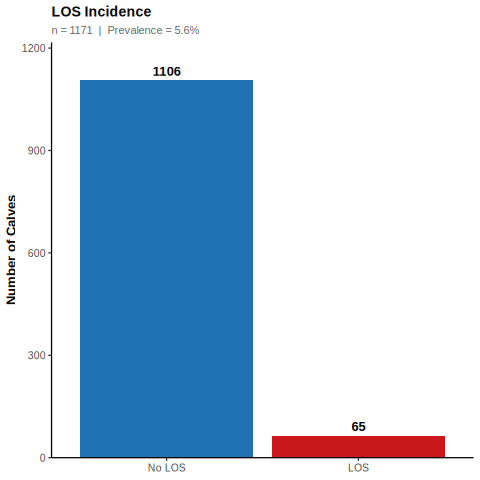

In [52]:
%%R
inc_df <- lab_farm_summary %>%
  dplyr::mutate(LOS_final = factor(LOS_final, levels = c(0, 1),
                                   labels = c("No LOS", "LOS")))

p_inc <- ggplot(inc_df, aes(x = LOS_final,
                             fill = LOS_final)) +
  geom_bar() +
  geom_text(stat = "count",
            aes(label = after_stat(count)),
            vjust = -0.5, fontface = "bold", size = 4.5) +
  scale_fill_manual(values = c("No LOS" = COL_BLUE,
                                "LOS"    = COL_RED),
                    guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.1))) +
  labs(
    title    = "LOS Incidence",
    subtitle = paste0("n = ", nrow(inc_df),
                      "  |  Prevalence = ",
                      round(mean(inc_df$LOS_final == "LOS") * 100, 1), "%"),
    x = NULL, y = "Number of Calves"
  ) +
  theme_los()

SaveFig(p_inc, "LOSIncidence")
print(p_inc)

##Pre-Model Prep

Cleaning and adding Different features before running the model

In [53]:
%%R
str(lab_farm_data)
summary(lab_farm_data)

tibble [1,171 × 96] (S3: tbl_df/tbl/data.frame)
 $ calf_ID                                        : chr [1:1171] "1292" "1365" "1383" "1387" ...
 $ recipient_ID                                   : chr [1:1171] "24057" "24461" "24446" "24476" ...
 $ recipient_calving_date                         : Date[1:1171], format: "2023-06-06" "2023-10-15" ...
 $ dam_ID                                         : num [1:1171] 23719 23719 24222 6288 24548 ...
 $ caesarean_indicator                            : Factor w/ 1 level "TRUE": NA NA NA NA NA NA NA NA NA NA ...
 $ navel_indicator                                : logi [1:1171] NA NA NA NA NA NA ...
 $ caesarean_binary                               : num [1:1171] 0 0 0 0 0 0 0 0 0 0 ...
 $ navel_treatment_binary                         : num [1:1171] 0 0 0 0 0 0 0 0 0 0 ...
 $ LOS_positive                                   : num [1:1171] 0 0 0 0 0 0 0 0 0 0 ...
 $ calf_gender_remark                             : chr [1:1171] "M-ET" "M-ET" "MET" 

In [54]:
%%R
lab_farm_data <- lab_farm_data %>%
  dplyr::mutate(
    LOS_final = factor(LOS_final, levels = c(0, 1),
                       labels = c("Healthy", "LOS")),
    is_pooled_batch = factor(ifelse(grepl("|||", dam_boviteq_number, fixed = TRUE),
                                    "Yes", "No"))
  ) %>%
  dplyr::select(-c(
    calf_ID, recipient_ID, donor_ID.x,
    sire_ID.x, dam_complete_name,
    dam_registration_number, sire_a_complete_name,
    embryo_lot, caesarean_indicator,
    navel_indicator, LOS_positive, LOS_remark_indicator,
    donor_level, follicles_1_4_mm, follicles_greater_than_15_mm
  )) %>%
  dplyr::mutate(
    dplyr::across(c(
      `0_to_2_layers_of_cumulus`, greater_than_or_equal_to_3_layers_of_cumulus,
      degenerated_oocytes, coasting_duration, total_aspirated_follicles,
      follicles_5_6_mm, follicles_7_10_mm, follicles_11_15_mm
    ), as.numeric),
    dam_birth_date         = as.Date(dam_birth_date),
    dam_age_at_opu_months  = as.numeric(stringr::str_extract(dam_age_at_opu, "\\d+")),
    embryo_age             = as.numeric(as.character(embryo_age)),
    embryo_age             = ifelse(embryo_age > 20, NA, embryo_age),
    embryo_grade           = as.factor(embryo_grade),
    lab                    = as.factor(lab),
    sire_a_semen_type      = as.factor(sire_a_semen_type),
    embryo_transfer_date   = as.Date(embryo_transfer_date),
    recipient_bred_date    = as.Date(recipient_bred_date),
    recipient_calving_date = as.Date(recipient_calving_date),
    recipient_birthdate    = as.Date(recipient_birthdate)
  )

str(lab_farm_data)
summary(lab_farm_data)

tibble [1,171 × 83] (S3: tbl_df/tbl/data.frame)
 $ recipient_calving_date                         : Date[1:1171], format: "2023-06-06" "2023-10-15" ...
 $ dam_ID                                         : num [1:1171] 23719 23719 24222 6288 24548 ...
 $ caesarean_binary                               : num [1:1171] 0 0 0 0 0 0 0 0 0 0 ...
 $ navel_treatment_binary                         : num [1:1171] 0 0 0 0 0 0 0 0 0 0 ...
 $ calf_gender_remark                             : chr [1:1171] "M-ET" "M-ET" "MET" "MET" ...
 $ LOS_final                                      : Factor w/ 2 levels "Healthy","LOS": 1 1 1 1 1 1 1 1 1 1 ...
 $ ET_status                                      : chr [1:1171] "ET" "ET" "ET" "ET" ...
 $ recipient_bred_date                            : Date[1:1171], format: "2022-09-06" "2023-01-15" ...
 $ embryo_transfer_date                           : Date[1:1171], format: "2022-09-13" "2023-01-22" ...
 $ recipient_heat_date                            : chr [1:1171] "MO

In [55]:
%%R
#features
#Embryo–recipient synchrony
lab_farm_data <- lab_farm_data %>%
  mutate(
    days_between_heat_and_transfer =
      as.numeric(embryo_transfer_date - recipient_bred_date),

    embryo_sync =
      embryo_age - days_between_heat_and_transfer,

    sync_abs = abs(embryo_sync),

    sync_category = case_when(
      sync_abs == 0 ~ "perfect",
      sync_abs == 1 ~ "moderate",
      sync_abs >= 2 ~ "poor",
      TRUE ~ NA_character_
    )
  )

#Recipient age before giving birth
lab_farm_data <- lab_farm_data %>%
  mutate(
    recipient_age_days =
      as.numeric(recipient_calving_date - recipient_birthdate),

    recipient_age_years = recipient_age_days / 365
  )

#Seasonal effect
lab_farm_data <- lab_farm_data %>%
  mutate(
    transfer_month = as.numeric(format(embryo_transfer_date, "%m")),
    season = case_when(
      transfer_month %in% c(12,1,2) ~ "winter",
      transfer_month %in% c(3,4,5) ~ "spring",
      transfer_month %in% c(6,7,8) ~ "summer",
      TRUE ~ "fall"
    )
  )

#Embryo quality ratios
lab_farm_data <- lab_farm_data %>%
  mutate(
    cleavage_rate = number_of_cleaved_embryos / total_structures_found,
    viability_rate = number_of_viable_embryos / total_structures_found,
    morula_rate = number_of_morulas / total_structures_found
  )

#Follicle distribution
lab_farm_data <- lab_farm_data %>%
  mutate(
    small_follicles = follicles_5_6_mm,
    large_follicles = follicles_11_15_mm,
    follicle_ratio = large_follicles / (small_follicles + 1) #follicle ratio
  )

#Oocyte Quality Ratio
lab_farm_data <- lab_farm_data %>%
  mutate(
    prop_good_cumulus =
      greater_than_or_equal_to_3_layers_of_cumulus / total_structures_found,

    prop_poor_cumulus =
      `0_to_2_layers_of_cumulus` / total_structures_found,

    cumulus_ratio =
      greater_than_or_equal_to_3_layers_of_cumulus /
      (`0_to_2_layers_of_cumulus` + 1)
  )

#Maturation to Fertilisation Time Ratio
lab_farm_data <- lab_farm_data %>%
  mutate(
    total_lab_time =
      in_vitro_maturation_duration +
      in_vitro_fertilisation_duration,

    maturation_to_fertilisation_ratio =
      in_vitro_maturation_duration /
      (in_vitro_fertilisation_duration + 1)
  )

  #efficiency
  lab_farm_data <- lab_farm_data %>%
  mutate(
    embryos_per_oocyte =
      number_of_viable_embryos / oocytes_in_maturation,

    cleavage_per_oocyte =
      number_of_cleaved_embryos / oocytes_in_maturation
  )

  #sire birth year
  lab_farm_data <- lab_farm_data %>%
  mutate(
    sire_birth_year = as.integer(format(as.Date(.data$sire_a_birth_date), "%Y"))
  )

  #embryo density
  lab_farm_data <- lab_farm_data %>%
  mutate(
    embryos_per_transfer = number_of_viable_embryos,
    embryo_density =
      number_of_viable_embryos / (days_between_heat_and_transfer + 1)
  )
#exclude FSH NA values (since it is showing up in the models)
lab_farm_data <- lab_farm_data %>%
  mutate(
    spo_program = dplyr::case_when(
      is.na(.data$spo_program) ~ "Unknown",
      trimws(as.character(.data$spo_program)) == "" ~ "Unknown",
      TRUE ~ as.character(.data$spo_program)
    ),
    spo_program = as.factor(.data$spo_program)
  )

lab_farm_data <- lab_farm_data %>%
  mutate(
    age_sync_interaction =
      recipient_age_years * sync_abs,

    embryo_age_vs_recipient_age =
      embryo_age / (recipient_age_years + 1)
  )

 #season sync
  lab_farm_data <- lab_farm_data %>%
  mutate(
    season_sync =
      interaction(season, sync_category)
  )

  #embryo grade
  lab_farm_data <- lab_farm_data %>%
  mutate(
    embryo_grade = as.character(.data$embryo_grade),
    embryo_grade = dplyr::if_else(
      .data$embryo_grade %in% c("1", "2"),
      .data$embryo_grade,
      NA_character_
    ),
    embryo_grade = factor(.data$embryo_grade, levels = c("1", "2"))
  )

#cleanup
lab_farm_data <- lab_farm_data %>%
  mutate(
    caesarean_binary = as.factor(caesarean_binary),
    navel_treatment_binary = as.factor(navel_treatment_binary),
    sync_category = as.factor(sync_category),
    season = as.factor(season),
    #convert transfer_month to a regular factor
    transfer_month = as.factor(as.character(transfer_month)),
     sire_age_missing = if_else(is.na(sire_a_age_at_semen_collection), 1, 0),
    sire_a_age_at_semen_collection = if_else(
      is.na(sire_a_age_at_semen_collection),
      median(sire_a_age_at_semen_collection, na.rm = TRUE),
      sire_a_age_at_semen_collection
  ))
  #creating a coloumn for gender and twins
  lab_farm_data <- lab_farm_data %>%
  mutate(
    calf_gender = case_when(
      grepl("^M|^m|/M", calf_gender_remark) ~ "Male",
      grepl("^F|^f|/F", calf_gender_remark) ~ "Female",
      TRUE ~ NA_character_
    ),

    #Keep twins separate because a Male Twin is different from a Male Single
    is_twin = if_else(
      grepl("/|TWIN|FF|MM", calf_gender_remark, ignore.case = TRUE), "Twin", "Single"
    )
  ) %>%
  mutate(
    calf_gender = as.factor(calf_gender),
    is_twin = as.factor(is_twin)
  )
#factor conversion
lab_farm_data$cumulus_expansion_post_maturation <-
  factor(lab_farm_data$cumulus_expansion_post_maturation)

str(lab_farm_data)
summary(lab_farm_data)

tibble [1,171 × 113] (S3: tbl_df/tbl/data.frame)
 $ recipient_calving_date                         : Date[1:1171], format: "2023-06-06" "2023-10-15" ...
 $ dam_ID                                         : num [1:1171] 23719 23719 24222 6288 24548 ...
 $ caesarean_binary                               : Factor w/ 2 levels "0","1": 1 1 1 1 1 1 1 1 1 1 ...
 $ navel_treatment_binary                         : Factor w/ 2 levels "0","1": 1 1 1 1 1 1 1 1 1 1 ...
 $ calf_gender_remark                             : chr [1:1171] "M-ET" "M-ET" "MET" "MET" ...
 $ LOS_final                                      : Factor w/ 2 levels "Healthy","LOS": 1 1 1 1 1 1 1 1 1 1 ...
 $ ET_status                                      : chr [1:1171] "ET" "ET" "ET" "ET" ...
 $ recipient_bred_date                            : Date[1:1171], format: "2022-09-06" "2023-01-15" ...
 $ embryo_transfer_date                           : Date[1:1171], format: "2022-09-13" "2023-01-22" ...
 $ recipient_heat_date               

In [56]:
%%R
install.packages("h2o")
library(h2o)
h2o.init()

(as ‘lib’ is unspecified)







	‘/tmp/Rtmpyk06B9/downloaded_packages’

----------------------------------------------------------------------

Your next step is to start H2O:
    > h2o.init()

For H2O package documentation, ask for help:
    > ??h2o

After starting H2O, you can use the Web UI at http://localhost:54321
For more information visit https://docs.h2o.ai

----------------------------------------------------------------------


Attaching package: ‘h2o’



    var



    day, hour, month, week, year



    hour, month, week, year



    cor, sd, var



    &&, %*%, %in%, ||, apply, as.factor, as.numeric, colnames,
    colnames<-, ifelse, is.character, is.factor, is.numeric, log,
    log10, log1p, log2, round, signif, trunc





H2O is not running yet, starting it now...

Note:  In case of errors look at the following log files:
    /tmp/Rtmpyk06B9/file2e90300e2a89/h2o_UnknownUser_started_from_r.out
    /tmp/Rtmpyk06B9/file2e90503d2238/h2o_UnknownUser_started_from_r.err


Starting H2O JVM and connecting: .... Connection successful!

R is connected to the H2O cluster: 
    H2O cluster uptime:         2 seconds 757 milliseconds 
    H2O cluster timezone:       Etc/UTC 
    H2O data parsing timezone:  UTC 
    H2O cluster version:        3.44.0.3 
    H2O cluster version age:    2 years, 9 months and 22 days 
    H2O cluster name:           H2O_started_from_R_root_jpg977 
    H2O cluster total nodes:    1 
    H2O cluster total memory:   3.15 GB 
    H2O cluster total cores:    2 
    H2O cluster allowed cores:  2 
    H2O cluster healthy:        TRUE 
    H2O Connection ip:          localhost 
    H2O Connection port:        54321 
    H2O Connection proxy:       NA 
    H2O Internal Security:      FALSE 
    R

Excluding varibales

In [57]:
%%R

library(dplyr)

#EXCLUDED VARIABLES
exclude_vars <- c(
  "recipient_calving_date", "approx_recipient_calving_date",
  "donor_number", "laboratory", "collection_site",
  "dam's_owner_complete_name", "navel_treatment_binary", "caesarean_binary",
  "calf_gender_remark", "sire_a_semen_lot", "dam_boviteq_number", "dam_ID",
  "boviteq_lab_ID", "performed_by", "sire_a_registration_number", "sire_a_semen_code",
  "recipient_bred_date", "embryo_transfer_date", "opu_date", "insemination_date",
  "embryo_collection_date", "flush_date", "dam_birth_date", "recipient_birthdate",
  "total_structures_found", "cleavage_percent", "morulas_percent",
  "embryos_percent", "days_between_heat_and_transfer", "preg_open_binary",
  "dam's_owner_short_name", "recipient_age_days", "dam_age_at_opu",
  "total_aspirated_follicles", "small_follicles", "large_follicles",
  "follicles_5_6_mm", "follicles_7_10_mm", "follicles_11_15_mm",
  "oocytes_in_maturation", "0_to_2_layers_of_cumulus",
  "greater_than_or_equal_to_3_layers_of_cumulus", "degenerated_oocytes",
  "number_of_cleaved_embryos", "number_of_morulas", "number_of_viable_embryos",
  "good_quality_morulas", "poor_quality_morulas", "potentially_freezable_embryos",
  "total_discarded", "total_frozens",
  "viability_rate", "morula_rate", "predictions_of_viable_embryos",
  "prop_good_cumulus", "prop_poor_cumulus",
  "cleavage_rate", "transfer_day_of_week", "season_sync",
  "sire_a_age_at_semen_collection", "transfer_month",
  "sync_abs", "age_sync_interaction", "embryo_age_vs_recipient_age",
  "is_twin", "lab", "sire_a_birth_date",
  "prop_poor_quality", "dam_atq_number",
  "in_vitro_maturation_duration",
  "in_vitro_fertilisation_duration",
  "is_pooled_batch","donor_ID.y", "sire_ID.y","total_lab_time",
  "maturation_to_fertilisation_ratio", "sire_a_breed_code","lot_number",
  "recipient_heat_time","sire_age_missing","embryo_sync","embryo_density"
)

#master data creation (used for all models)
master_data <- lab_farm_data %>%
  dplyr::select(-any_of(exclude_vars)) %>%
  dplyr::select(where(~ mean(is.na(.)) < 0.30)) %>%
  dplyr::select(where(~ n_distinct(., na.rm = TRUE) > 1)) %>%
  dplyr::filter(!is.na(LOS_final))

#formatting
master_data$LOS_final <- as.character(master_data$LOS_final)
master_data$LOS_final[master_data$LOS_final != "LOS"] <- "Healthy"
master_data$LOS_final <- factor(master_data$LOS_final, levels = c("Healthy", "LOS"))

  glimpse(master_data)
  summary(master_data)

Rows: 1,171
Columns: 25
$ LOS_final                                       <fct> Healthy, Healthy, Heal…
$ recipient_heat_date                             <chr> "MON", "SAT", "THURS",…
$ embryo_age                                      <dbl> 7, 7, 7, 6, 6, 7, 6, 7…
$ embryo_grade                                    <fct> 1, 1, 1, 1, 1, 1, 1, 1…
$ recipient_cycle_date                            <dbl> 8, 8, 8, 8, 7, 8, 8, 8…
$ dam_starting_state                              <chr> "P4 Injected", "P4 Inj…
$ sire_a_semen_type                               <fct> Conventional, Conventi…
$ spo_program                                     <fct> P300F, 2.5 cc FSH x 6,…
$ coasting_duration                               <dbl> 43, 40, 40, 40, 40, 40…
$ in_vitro_maturation_time                        <dbl> 820, 642, 849, 849, 76…
$ cumulus_expansion_post_maturation               <fct> A, A, A, A, A, A, A, A…
$ heparin_concentration_in_fertilisation_droplets <dbl> 2.00, 3.00, 1.50, 1.50…
$ in_vitro_ferti

In [58]:
%%R

output_dir <- "/content/drive/Shareddrives/Bovi-Analytics/B&B 2025 Spring semester"
if (!dir.exists(output_dir)) {
  dir.create(output_dir, recursive = TRUE)
}

write.csv(master_data, file.path(output_dir, "master_data.csv"), row.names = FALSE)

Model Training

##H2O Model

In [59]:
%%R

library(h2o)
library(dplyr)

BALANCE_CLASSES <- TRUE #for imbalanced dataset
AML_SEED <- 123L
MAX_MODELS <- 40L #changed total number of models during re reuns

#70/15/15 train/valid/test split
set.seed(123)
idx_healthy <- which(master_data$LOS_final == "Healthy")
idx_los <- which(master_data$LOS_final == "LOS")
split_fn <- function(idx) {
  n <- length(idx)
  idx <- sample(idx)
  n_train <- floor(0.7 * n)
  n_valid <- floor(0.15 * n)

  list(
    train = idx[1:n_train],
    valid = idx[(n_train+1):(n_train+n_valid)],
    test  = idx[(n_train+n_valid+1):n]
  )
}

h <- split_fn(idx_healthy)
l <- split_fn(idx_los)

train_df <- master_data[c(h$train, l$train), ]
valid_df <- master_data[c(h$valid, l$valid), ]
test_df  <- master_data[c(h$test,  l$test), ]

#H2O
h2o.init(nthreads = -1, max_mem_size = "8G")

train_hf <- as.h2o(train_df)
valid_hf <- as.h2o(valid_df)
test_hf  <- as.h2o(test_df)

y <- "LOS_final"
x <- setdiff(colnames(train_hf), y)

train_hf[, y] <- as.factor(train_hf[, y])
valid_hf[, y] <- as.factor(valid_hf[, y])
test_hf[, y]  <- as.factor(test_hf[, y])

#autoML
aml <- h2o.automl(
  x = x,
  y = y,
  training_frame = train_hf,
  validation_frame = valid_hf,
  leaderboard_frame = valid_hf,
  max_models = MAX_MODELS,
  seed = AML_SEED,
  balance_classes = BALANCE_CLASSES,
  nfolds = 5, #best for cross validation
  sort_metric = "AUCPR",
  stopping_metric = "AUCPR" #better for class imbalance dataset
)

best_model <- aml@leader
print(aml@leaderboard)

 Connection successful!

R is connected to the H2O cluster: 
    H2O cluster uptime:         3 seconds 641 milliseconds 
    H2O cluster timezone:       Etc/UTC 
    H2O data parsing timezone:  UTC 
    H2O cluster version:        3.44.0.3 
    H2O cluster version age:    2 years, 9 months and 22 days 
    H2O cluster name:           H2O_started_from_R_root_jpg977 
    H2O cluster total nodes:    1 
    H2O cluster total memory:   3.15 GB 
    H2O cluster total cores:    2 
    H2O cluster allowed cores:  2 
    H2O cluster healthy:        TRUE 
    H2O Connection ip:          localhost 
    H2O Connection port:        54321 
    H2O Connection proxy:       NA 
    H2O Internal Security:      FALSE 
    R Version:                  R version 4.6.1 (2026-06-24) 

  |======================================================================| 100%
  |======================================================================| 100%
  |=================================================================

In [61]:
%%R
library(pmsampsize)
n_events <- sum(master_data$LOS_final == "LOS")
n_pred   <- ncol(master_data) - 1
epv      <- n_events / n_pred
cat("Events (LOS):", n_events, "\n")
cat("Predictors:  ", n_pred, "\n")
cat("EPV:         ", round(epv, 2), "  (≥10 recommended)\n\n")
pmsampsize(type       = "b",
           prevalence = n_events / nrow(master_data),
           parameters = n_pred,
           cstatistic = 0.77)   # best model AUC from leaderboard

Events (LOS): 65 
Predictors:   24 
EPV:          2.71   (≥10 recommended)

Given input C-statistic = 0.77  & prevalence = 0.05550811  
Cox-Snell R-sq = 0.0535  
 
NB: Assuming 0.05 acceptable difference in apparent & adjusted R-squared 
NB: Assuming 0.05 margin of error in estimation of intercept 
NB: Events per Predictor Parameter (EPP) assumes prevalence = 0.05550811  
 
           Samp_size Shrinkage Parameter CS_Rsq Max_Rsq Nag_Rsq  EPP
Criteria 1      3917     0.900        24 0.0535   0.349   0.153 9.06
Criteria 2      1327     0.754        24 0.0535   0.349   0.153 3.07
Criteria 3        81     0.900        24 0.0535   0.349   0.153 0.19
Final           3917     0.900        24 0.0535   0.349   0.153 9.06
 
 Minimum sample size required for new model development based on user inputs = 3917, 
 with 218 events (assuming an outcome prevalence = 0.05550811) and an EPP = 9.06 
 
 

In [62]:
%%R
library(openxlsx)

miss_df <- data.frame(
  Variable   = names(master_data),
  N_Missing  = sapply(master_data, function(x) sum(is.na(x))),
  Pct_Missing = round(sapply(master_data, function(x) mean(is.na(x)) * 100), 1)
) %>%
  dplyr::arrange(dplyr::desc(Pct_Missing)) %>%
  dplyr::filter(Pct_Missing > 0)

miss_df$Variable <- CleanLabel(miss_df$Variable)

print(miss_df)
write.xlsx(miss_df, file.path(TabDir, "MissingnessTable.xlsx"), rowNames = FALSE)
cat("Saved: MissingnessTable.xlsx\n")

                                                                         Variable
in_vitro_fertilisation_time                                    IVF Duration (min)
recipient_age_years                                         Recipient Age (years)
dam_starting_state                                             Dam Starting State
sire_birth_year                                                   Sire Birth Year
embryos_per_oocyte                                             Embryos per Oocyte
embryos_per_transfer                                         Embryos per Transfer
sire_a_semen_type                                               Sire A Semen Type
coasting_duration                                         Coasting Duration (min)
in_vitro_maturation_time                                       IVM Duration (min)
cumulus_expansion_post_maturation               Cumulus Expansion Post Maturation
heparin_concentration_in_fertilisation_droplets     Heparin Concentration (µg/mL)
stripping_time  

In [63]:
%%R
lb <- as.data.frame(aml@leaderboard)
xgb_id <- lb$model_id[grep("XGBoost", lb$model_id)][1]
best_model <- h2o.getModel(xgb_id)
cat("Best model locked:", xgb_id, "\n")
cat("Test AUC:  ", h2o.auc(h2o.performance(best_model, newdata=test_hf)), "\n")
cat("Test AUCPR:", h2o.aucpr(h2o.performance(best_model, newdata=test_hf)), "\n")

Best model locked: XGBoost_grid_1_AutoML_2_20261012_194925_model_10 
Test AUC:   0.7177463 
Test AUCPR: 0.3100958 


  |======================================================================| 100%


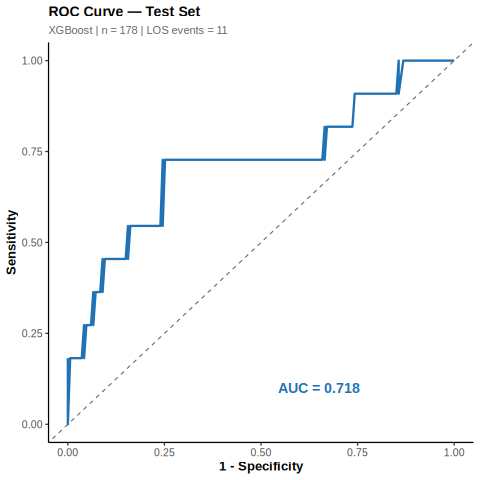

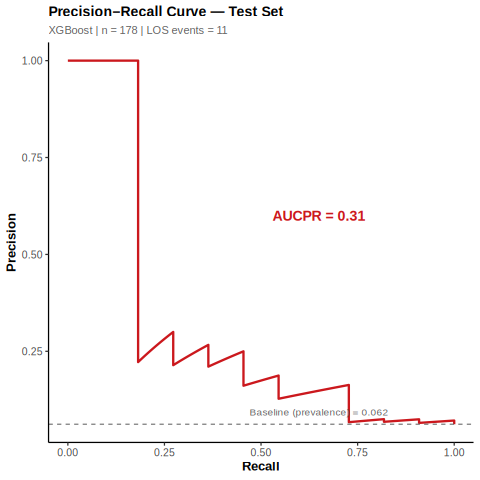

In [64]:
%%R
library(pROC); library(precrec); library(ggplot2)

test_preds  <- as.data.frame(h2o.predict(best_model, test_hf))
test_labels <- as.numeric(test_df$LOS_final == "LOS")
pred_prob   <- test_preds$LOS

#  ROC Curve
roc_obj <- pROC::roc(test_labels, pred_prob, quiet = TRUE)
auc_val <- round(pROC::auc(roc_obj), 3)
roc_df  <- data.frame(specificity = roc_obj$specificities,
                      sensitivity = roc_obj$sensitivities)

p_roc <- ggplot(roc_df, aes(x = 1 - specificity, y = sensitivity)) +
  geom_line(colour = COL_BLUE, linewidth = 1.1) +
  geom_abline(linetype = "dashed", colour = COL_GREY) +
  annotate("text", x = 0.65, y = 0.1,
           label = paste0("AUC = ", auc_val),
           size = 5, colour = COL_BLUE, fontface = "bold") +
  labs(title    = "ROC Curve \u2014 Test Set",
       subtitle = paste0("XGBoost | n = ", nrow(test_df),
                         " | LOS events = ", sum(test_labels)),
       x = "1 - Specificity", y = "Sensitivity") +
  theme_los()

SaveFig(p_roc, "RocCurve")
print(p_roc)

#  PR Curve
mmdata_obj <- precrec::mmdata(pred_prob, test_labels)
pr_obj     <- precrec::evalmod(mmdata_obj)
pr_df      <- as.data.frame(pr_obj) %>% dplyr::filter(type == "PRC")
aucpr_val  <- round(h2o.aucpr(h2o.performance(best_model, newdata = test_hf)), 3)
prevalence <- round(mean(test_labels), 3)

p_pr <- ggplot(pr_df, aes(x = x, y = y)) +
  geom_line(colour = COL_RED, linewidth = 1.1) +
  geom_hline(yintercept = prevalence, linetype = "dashed", colour = COL_GREY) +
  annotate("text", x = 0.65, y = prevalence + 0.03,
           label = paste0("Baseline (prevalence) = ", prevalence),
           size = 3.5, colour = COL_GREY) +
  annotate("text", x = 0.65, y = 0.6,
           label = paste0("AUCPR = ", aucpr_val),
           size = 5, colour = COL_RED, fontface = "bold") +
  labs(title    = "Precision\u2013Recall Curve \u2014 Test Set",
       subtitle = paste0("XGBoost | n = ", nrow(test_df),
                         " | LOS events = ", sum(test_labels)),
       x = "Recall", y = "Precision") +
  theme_los()

SaveFig(p_pr, "PrCurve")
print(p_pr)

Threshold and Confusion Matrix GBM

  |======================================================================| 100%

TEST RESULTS
AUC: 0.7177463 
PR-AUC: 0.3100958 
LogLoss: 0.2391678 

VALIDATION PERFORMANCE
AUC: 0.7717172 
PR-AUC: 0.3014321 
LogLoss: 0.2615866 

Threshold at recall >= 0.7 : 0.07179284 
   threshold precision    recall        f1 accuracy specificity absolute_mcc
1 0.07179284 0.1029412 0.7777778 0.1818182 0.637931    0.630303     0.185226
  tns fns fps tps       tpr      fpr      tnr       fnr
1 104   2  61   7 0.7777778 0.369697 0.630303 0.2222222

CONFUSION MATRIX
         Actual
Predicted Healthy LOS
  Healthy     104   3
  LOS          63   8


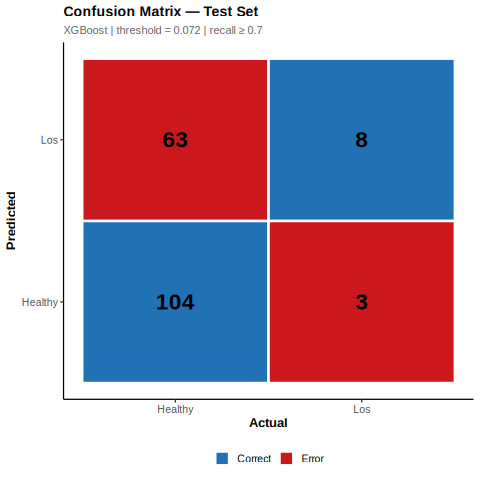

In [65]:
%%R
library(dplyr); library(ggplot2)

pred_df        <- as.data.frame(h2o.predict(best_model, test_hf))
test_df_r      <- as.data.frame(test_hf)
pred_df$actual <- test_df_r$LOS_final
pred_df$prob_LOS <- pred_df$LOS

perf_test  <- h2o.performance(best_model, newdata = test_hf)
perf_valid <- h2o.performance(best_model, newdata = valid_hf)
cat("\nTEST RESULTS\n")
cat("AUC:",     h2o.auc(perf_test),   "\n")
cat("PR-AUC:",  h2o.aucpr(perf_test), "\n")
cat("LogLoss:", h2o.logloss(perf_test), "\n")
cat("\nVALIDATION PERFORMANCE\n")
cat("AUC:",     h2o.auc(perf_valid),   "\n")
cat("PR-AUC:",  h2o.aucpr(perf_valid), "\n")
cat("LogLoss:", h2o.logloss(perf_valid), "\n")

thz <- as.data.frame(h2o.thresholds_and_metric_scores(perf_valid))
target_recall <- 0.70
best_row <- thz %>%
  filter(tpr >= target_recall) %>%
  arrange(desc(precision)) %>%
  slice(1)
best_threshold <- best_row$threshold
cat("\nThreshold at recall >=", target_recall, ":", best_threshold, "\n")

cols_to_show <- intersect(
  c("threshold","precision","recall","f1","accuracy",
    "specificity","absolute_mcc","tns","fns","fps","tps","tpr","fpr","tnr","fnr"),
  colnames(best_row))
print(best_row[, cols_to_show])

pred_class <- ifelse(pred_df$prob_LOS >= best_threshold, "LOS", "Healthy")
cm <- table(Predicted = pred_class, Actual = pred_df$actual)
cat("\nCONFUSION MATRIX\n"); print(cm)

# Visualise
cm_df <- as.data.frame(cm)
cm_df$Fill <- ifelse(cm_df$Predicted == cm_df$Actual, "Correct", "Error")

p_cm <- ggplot(cm_df, aes(x = Actual, y = Predicted, fill = Fill)) +
  geom_tile(colour = "white", linewidth = 1.2) +
  geom_text(aes(label = Freq), size = 8, fontface = "bold") +
  scale_fill_manual(values = c("Correct" = COL_BLUE, "Error" = COL_RED),
                    name = NULL) +
  scale_x_discrete(labels = CleanLabel) +
  scale_y_discrete(labels = CleanLabel) +
  labs(title    = "Confusion Matrix \u2014 Test Set",
       subtitle = paste0("XGBoost | threshold = ", round(best_threshold, 3),
                         " | recall \u2265 ", target_recall),
       x = "Actual", y = "Predicted") +
  theme_los() +
  theme(legend.position = "bottom")

SaveFig(p_cm, "ConfusionMatrix")
print(p_cm)

##GBM


SELECTED GBM MODEL:
[1] "GBM_3_AutoML_2_20261012_194925"

GBM TEST PERFORMANCE:
AUC: 0.7093087 
PR-AUC: 0.1191928 
LogLoss: 0.3014678 

TOP 15 VARIABLE IMPORTANCE:
                                          variable relative_importance
1                              recipient_age_years           239.87677
2                                      spo_program           163.67821
3                      in_vitro_fertilisation_time           141.70876
4                                    cumulus_ratio           129.68198
5                                           season           118.10978
6                                prop_good_quality            83.66571
7                                    sync_category            82.40424
8                               embryos_per_oocyte            76.52213
9                             embryos_per_transfer            71.45367
10                             cleavage_per_oocyte            65.11967
11                        in_vitro_maturation_time    

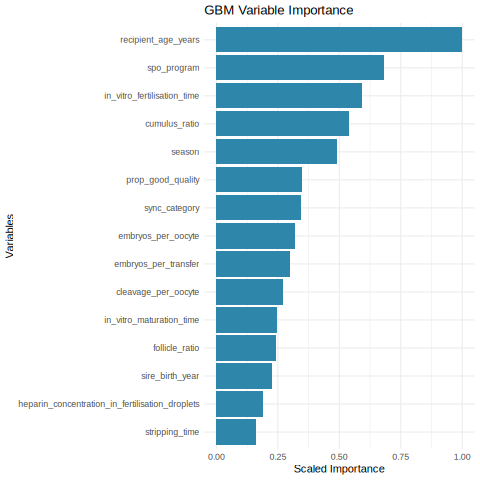

In [66]:
%%R

library(h2o)
library(dplyr)
library(ggplot2)

#Get best GBM from AutoML leaderboard (by PR-AUC)
gbm_id <- as.data.frame(aml@leaderboard) %>%
  filter(grepl("GBM", model_id)) %>%
  arrange(desc(aucpr)) %>%
  slice(1) %>%
  pull(model_id)

gbm_model <- h2o.getModel(gbm_id)

cat("\nSELECTED GBM MODEL:\n")
print(gbm_id)

#test data performance
perf_gbm <- h2o.performance(gbm_model, newdata = test_hf) #model was evaluated on test data

cat("\nGBM TEST PERFORMANCE:\n")
cat("AUC:", h2o.auc(perf_gbm), "\n")
cat("PR-AUC:", h2o.aucpr(perf_gbm), "\n")
cat("LogLoss:", h2o.logloss(perf_gbm), "\n")

#VARIABLE IMPORTANCE
vi <- as.data.frame(h2o.varimp(gbm_model))
cat("\nTOP 15 VARIABLE IMPORTANCE:\n")
print(
  vi %>%
    select(
      variable,
      relative_importance,
      scaled_importance,
      percentage
    ) %>%
    slice(1:15)
)
#plot GBM
top_vi <- vi %>%
  slice(1:15)
ggplot(top_vi,
       aes(x = reorder(variable, scaled_importance),
           y = scaled_importance)) +
  geom_col(fill = "#2E86AB") +
  coord_flip() +
  theme_minimal() +
  labs(title = "GBM Variable Importance",
       x = "Variables",
       y = "Scaled Importance")

##GBM-SHAP


TOP VARIABLES FOR SHAP:
 [1] "recipient_age_years"         "spo_program"                
 [3] "in_vitro_fertilisation_time" "cumulus_ratio"              
 [5] "season"                      "prop_good_quality"          
 [7] "sync_category"               "embryos_per_oocyte"         
 [9] "embryos_per_transfer"        "cleavage_per_oocyte"        


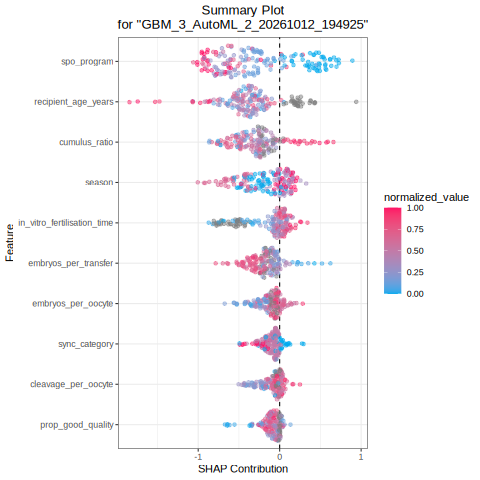

In [67]:
%%R

#Top variables from GBM
vi <- as.data.frame(h2o.varimp(gbm_model))

top_vars <- head(vi$variable, 10)

cat("\nTOP VARIABLES FOR SHAP:\n")
print(top_vars)

#SHAP summary plot for top variables
h2o.shap_summary_plot(
  gbm_model,
  newdata = test_hf,
  columns = top_vars
)

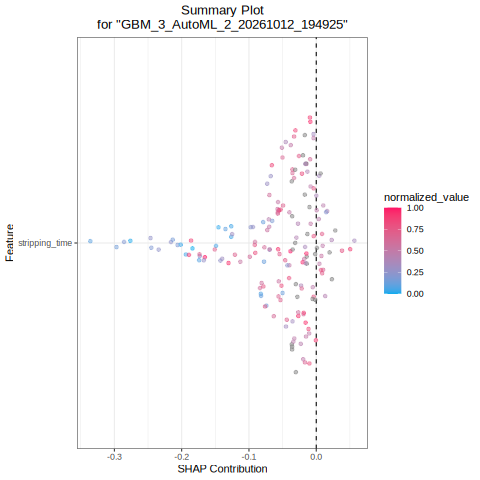

In [68]:
%%R

#GBM Model - to test individual SHAP plotting over combined
lb <- as.data.frame(aml@leaderboard)

gbm_id <- lb %>%
  dplyr::filter(grepl("GBM", model_id)) %>%
  dplyr::slice(1) %>%
  dplyr::pull(model_id)

gbm_model <- h2o.getModel(gbm_id)

#Individual SHAP
h2o.shap_summary_plot(
  gbm_model,
  newdata = test_hf,
  columns = "stripping_time"
)

##XGBOOST


SELECTED XGBoost MODEL:
[1] "XGBoost_grid_1_AutoML_2_20261012_194925_model_10"

XGBOOST TEST PERFORMANCE:
AUC: 0.7177463 
PR-AUC: 0.3100958 
LogLoss: 0.2391678 

TOP 15 VARIABLE IMPORTANCE:
                                          variable relative_importance
1                              recipient_age_years           600.38531
2                                    cumulus_ratio           398.84955
3                      in_vitro_fertilisation_time           320.99966
4                              cleavage_per_oocyte           305.84311
5                            dam_age_at_opu_months           225.74564
6                                prop_good_quality           207.20575
7                                   stripping_time           174.61781
8  heparin_concentration_in_fertilisation_droplets           174.08438
9                             embryos_per_transfer           173.48344
10                              embryos_per_oocyte           170.63669
11                          

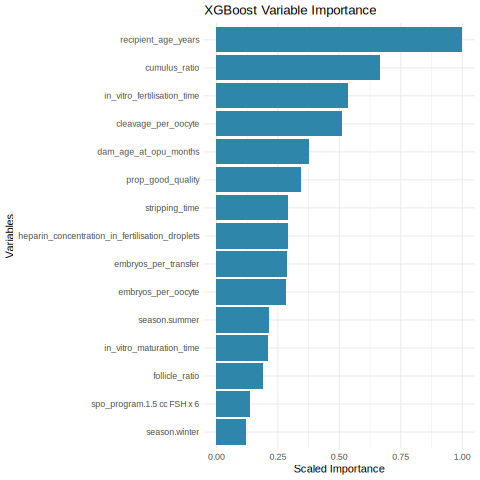

In [69]:
%%R

library(h2o)
library(dplyr)
library(ggplot2)

#Get best xgboost from AutoML leaderboard (by PR-AUC)
xgb_id <- as.data.frame(aml@leaderboard) %>%
  filter(grepl("XGBoost", model_id)) %>%
  arrange(desc(aucpr)) %>%
  slice(1) %>%
  pull(model_id)

xgb_model <- h2o.getModel(xgb_id)

cat("\nSELECTED XGBoost MODEL:\n")
print(xgb_id)

#test data performance
perf_xgb <- h2o.performance(xgb_model, newdata = test_hf) #model was evaluated on test data

cat("\nXGBOOST TEST PERFORMANCE:\n")
cat("AUC:", h2o.auc(perf_xgb), "\n")
cat("PR-AUC:", h2o.aucpr(perf_xgb), "\n")
cat("LogLoss:", h2o.logloss(perf_xgb), "\n")

#VARIABLE IMPORTANCE
vi <- as.data.frame(h2o.varimp(xgb_model))
cat("\nTOP 15 VARIABLE IMPORTANCE:\n")
print(
  vi %>%
    select(
      variable,
      relative_importance,
      scaled_importance,
      percentage
    ) %>%
    slice(1:15)
)
#plot XGB
top_vi <- vi %>%
  slice(1:15)
ggplot(top_vi,
       aes(x = reorder(variable, scaled_importance),
           y = scaled_importance)) +
  geom_col(fill = "#2E86AB") +
  coord_flip() +
  theme_minimal() +
  labs(title = "XGBoost Variable Importance",
       x = "Variables",
       y = "Scaled Importance")


TOP 15 VARIABLE IMPORTANCE:
                                          variable relative_importance
1                              recipient_age_years           600.38531
2                                    cumulus_ratio           398.84955
3                      in_vitro_fertilisation_time           320.99966
4                              cleavage_per_oocyte           305.84311
5                            dam_age_at_opu_months           225.74564
6                                prop_good_quality           207.20575
7                                   stripping_time           174.61781
8  heparin_concentration_in_fertilisation_droplets           174.08438
9                             embryos_per_transfer           173.48344
10                              embryos_per_oocyte           170.63669
11                                   season.summer           127.26993
12                        in_vitro_maturation_time           125.75520
13                                  follicle_rat

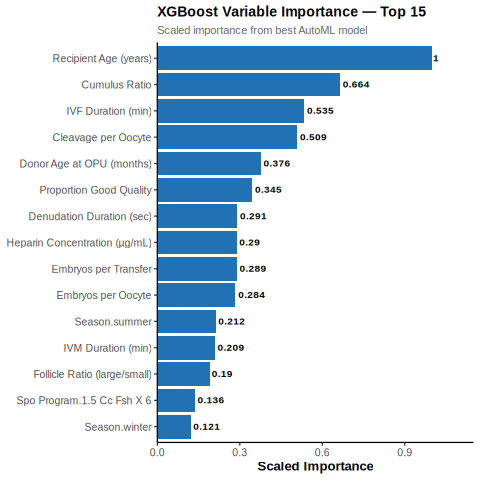

In [70]:
%%R
library(h2o); library(dplyr); library(ggplot2)

vi <- as.data.frame(h2o.varimp(best_model))
cat("\nTOP 15 VARIABLE IMPORTANCE:\n")
print(vi %>% select(variable, relative_importance, scaled_importance, percentage) %>% slice(1:15))

top_vi <- vi %>%
  slice(1:15) %>%
  mutate(label = CleanLabel(variable))

p_vi <- ggplot(top_vi, aes(x = reorder(label, scaled_importance), y = scaled_importance)) +
  geom_col(fill = COL_BLUE) +
  geom_text(aes(label = round(scaled_importance, 3)),
            hjust = -0.1, size = 3.5, fontface = "bold") +
  coord_flip() +
  scale_y_continuous(expand = expansion(mult = c(0, 0.15))) +
  labs(title    = "XGBoost Variable Importance \u2014 Top 15",
       subtitle = "Scaled importance from best AutoML model",
       x = NULL, y = "Scaled Importance") +
  theme_los()

SaveFig(p_vi, "VariableImportance")
print(p_vi)

In [71]:
%%R
#check SOV and season in the rest of the list to see if it's dummy variables
vi <- as.data.frame(h2o.varimp(xgb_model))

vi[grep("^season|^spo_program", vi$variable), ]

                     variable relative_importance scaled_importance
11              season.summer          127.269928       0.211980415
14 spo_program.1.5 cc FSH x 6           81.603683       0.135918853
15              season.winter           72.626930       0.120967200
20   spo_program.2 cc FSH x 6           34.267056       0.057075106
26                season.fall           17.763863       0.029587437
28              season.spring           16.343330       0.027221403
29        spo_program.Unknown           14.603735       0.024323938
30          spo_program.P300F            8.089988       0.013474660
31          spo_program.P240F            2.002428       0.003335238
     percentage
11 0.0343411752
14 0.0220190774
15 0.0195968850
20 0.0092462609
26 0.0047932134
28 0.0044099119
29 0.0039405178
30 0.0021829170
31 0.0005403141


##XGBoost-SHAP

In [143]:
%%R
cat(names(as.data.frame(test_hf)), sep="\n")

LOS_final
recipient_heat_date
embryo_age
embryo_grade
recipient_cycle_date
dam_starting_state
sire_a_semen_type
spo_program
coasting_duration
in_vitro_maturation_time
cumulus_expansion_post_maturation
heparin_concentration_in_fertilisation_droplets
in_vitro_fertilisation_time
stripping_time
prop_good_quality
dam_age_at_opu_months
sync_category
recipient_age_years
season
follicle_ratio
cumulus_ratio
embryos_per_oocyte
cleavage_per_oocyte
sire_birth_year
embryos_per_transfer


In [144]:
%%R
cat("spo_program levels:", levels(as.data.frame(test_hf)$spo_program), "\n")
cat("sync_category levels:", levels(as.data.frame(test_hf)$sync_category), "\n")
cat("season levels:", levels(as.data.frame(test_hf)$season), "\n")

spo_program levels: 1.5 cc FSH x 6 2 cc FSH x 6 2.5 cc FSH x 6 3 cc FSH x 6 Custom P180F P240F P300F Unknown 
sync_category levels: moderate perfect poor 
season levels: fall spring summer winter 


  |======================================================================| 100%
Orientation inferred to be along y-axis; override with
`position_quasirandom(orientation = 'x')`
Orientation inferred to be along y-axis; override with
`position_quasirandom(orientation = 'x')`


Orientation inferred to be along y-axis; override with
`position_quasirandom(orientation = 'x')`


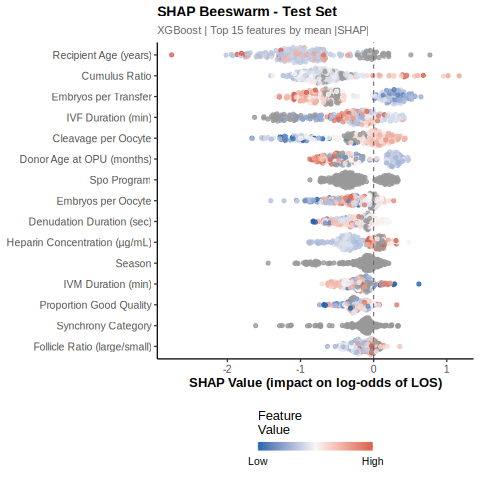

In [146]:
%%R
library(ggplot2); library(dplyr); library(tidyr); library(ggbeeswarm)

# SHAP values
shap_values <- as.data.frame(h2o.predict_contributions(best_model, test_hf))
shap_mat    <- shap_values %>% select(-BiasTerm)

# Numeric feature values for colour scaling (before pivot)
test_vals <- as.data.frame(test_hf) %>% select(-LOS_final)
numeric_cols <- names(test_vals)[sapply(test_vals, is.numeric)]

# Scale numeric columns separately
test_scaled <- test_vals %>%
  mutate(across(all_of(numeric_cols), ~ as.numeric(scale(.x)))) %>%
  mutate(across(everything(), as.character)) %>%
  mutate(row_id = row_number()) %>%
  pivot_longer(-row_id, names_to = "variable", values_to = "feature_val_scaled")

# SHAP long
shap_long <- shap_mat %>%
  mutate(row_id = row_number()) %>%
  pivot_longer(-row_id, names_to = "variable", values_to = "shap") %>%
  left_join(test_scaled, by = c("row_id", "variable")) %>%
  mutate(feature_val_scaled = suppressWarnings(as.numeric(feature_val_scaled)))

# Top 15 by mean |SHAP|
top_vars <- shap_long %>%
  group_by(variable) %>%
  summarise(mean_abs_shap = mean(abs(shap), na.rm = TRUE)) %>%
  arrange(desc(mean_abs_shap)) %>%
  slice(1:15) %>%
  pull(variable)

shap_plot_df <- shap_long %>%
  filter(variable %in% top_vars) %>%
  mutate(label = CleanLabel(variable),
         label = factor(label, levels = CleanLabel(rev(top_vars))))

p_shap <- ggplot(shap_plot_df,
                 aes(x = shap, y = label, colour = feature_val_scaled)) +
  geom_quasirandom(groupOnX = FALSE, size = 1.8, alpha = 0.8) +
  scale_colour_gradient2(
  low      = "#2166AC",   # strong blue
  mid      = "#F7F7F7",   # near-white centre
  high     = "#D6604D",   # strong red
  midpoint = 0,
  limits   = c(-2, 2),
  oob      = scales::squish,
  na.value = "grey60",
  name     = "Feature\nValue",
  breaks   = c(-2, 0, 2),
  labels   = c("Low", "", "High"),
  guide    = guide_colourbar(
    title.position = "top",
    barwidth       = 8,
    barheight      = 0.6,
    ticks          = FALSE
  )
) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = COL_GREY) +
  labs(title    = "SHAP Beeswarm - Test Set",
       subtitle = "XGBoost | Top 15 features by mean |SHAP|",
       x = "SHAP Value (impact on log-odds of LOS)",
       y = NULL) +
  theme_los()

SaveFig(p_shap, "ShapBeeswarm")
print(p_shap)

Orientation inferred to be along y-axis; override with
`position_quasirandom(orientation = 'x')`
Orientation inferred to be along y-axis; override with
`position_quasirandom(orientation = 'x')`


Orientation inferred to be along y-axis; override with
`position_quasirandom(orientation = 'x')`


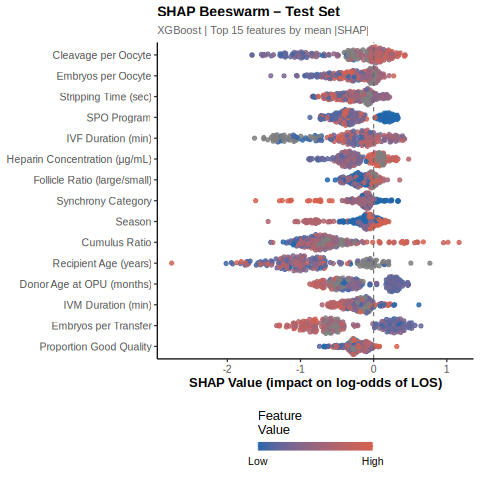

In [151]:
%%R
# Get the h2o plot and extract its data
p_raw <- h2o.shap_summary_plot(xgb_model, newdata=test_hf, columns=top_vars)
plot_data <- p_raw$data

# Apply clean labels
plot_data <- plot_data %>%
  mutate(feature = recode(feature,
    "recipient_age_years"                             = "Recipient Age (years)",
    "cumulus_ratio"                                   = "Cumulus Ratio",
    "in_vitro_fertilisation_time"                     = "IVF Duration (min)",
    "cleavage_per_oocyte"                             = "Cleavage per Oocyte",
    "dam_age_at_opu_months"                           = "Donor Age at OPU (months)",
    "prop_good_quality"                               = "Proportion Good Quality",
    "stripping_time"                                  = "Stripping Time (sec)",
    "heparin_concentration_in_fertilisation_droplets" = "Heparin Concentration (µg/mL)",
    "embryos_per_transfer"                            = "Embryos per Transfer",
    "embryos_per_oocyte"                              = "Embryos per Oocyte",
    "season.summer"                                   = "Season: Summer",
    "in_vitro_maturation_time"                        = "IVM Duration (min)",
    "follicle_ratio"                                  = "Follicle Ratio (large/small)",
    "spo_program.1.5 cc FSH x 6"                     = "SPO: 1.5cc FSH×6",
    "season.winter"                                   = "Season: Winter",
    "season"                                          = "Season",
    "spo_program"                                     = "SPO Program",
    "sync_category"                                   = "Synchrony Category"
  )) %>%
  mutate(feature = factor(feature, levels=rev(unique(feature))))

p_shap <- ggplot(plot_data, aes(x=contribution, y=feature, colour=normalized_value)) +
  geom_quasirandom(groupOnX=FALSE, size=1.8, alpha=0.85) +
  scale_colour_gradient(low="#2166AC", high="#D6604D",
    name="Feature\nValue", breaks=c(0,1), labels=c("Low","High"),
    guide=guide_colourbar(title.position="top", barwidth=8, barheight=0.6, ticks=FALSE)) +
  geom_vline(xintercept=0, linetype="dashed", colour=COL_GREY) +
  labs(title="SHAP Beeswarm – Test Set",
       subtitle="XGBoost | Top 15 features by mean |SHAP|",
       x="SHAP Value (impact on log-odds of LOS)", y=NULL) +
  theme_los() +
  theme(legend.position="bottom")

SaveFig(p_shap, "ShapBeeswarm")
print(p_shap)

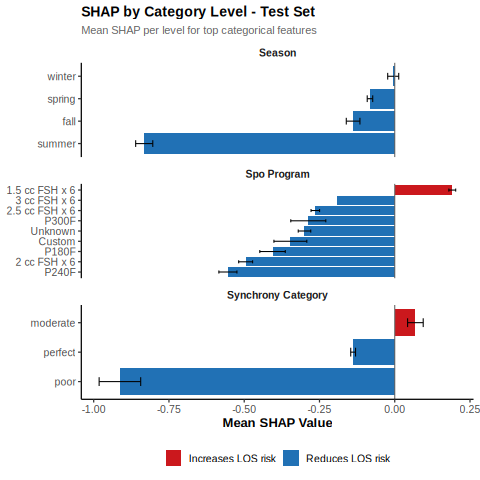

In [73]:
%%R
# Pull actual feature values for categorical vars from test_df
cat_shap <- shap_long %>%
  filter(variable %in% c("spo_program", "season", "sync_category")) %>%
  left_join(
    as.data.frame(test_hf) %>%
      select(spo_program, season, sync_category) %>%
      mutate(row_id = row_number()),
    by = "row_id"
  ) %>%
  mutate(level = case_when(
    variable == "spo_program"    ~ as.character(spo_program),
    variable == "season"         ~ as.character(season),
    variable == "sync_category"  ~ as.character(sync_category)
  )) %>%
  filter(!is.na(level)) %>%
  group_by(variable, level) %>%
  summarise(mean_shap = mean(shap), se = sd(shap)/sqrt(n()), .groups="drop") %>%
  mutate(label = CleanLabel(variable),
         direction = ifelse(mean_shap > 0, "Increases LOS risk", "Reduces LOS risk"))

p_cat_shap <- ggplot(cat_shap,
                     aes(x = reorder(level, mean_shap),
                         y = mean_shap, fill = direction)) +
  geom_col() +
  geom_errorbar(aes(ymin = mean_shap - se, ymax = mean_shap + se),
                width = 0.3) +
  geom_hline(yintercept = 0, colour = COL_GREY) +
  scale_fill_manual(values = c("Increases LOS risk" = COL_RED,
                               "Reduces LOS risk"   = COL_BLUE),
                    name = NULL) +
  facet_wrap(~ label, scales = "free_y", ncol = 1) +
  coord_flip() +
  labs(title    = "SHAP by Category Level - Test Set",
       subtitle = "Mean SHAP per level for top categorical features",
       x = NULL, y = "Mean SHAP Value") +
  theme_los()

SaveFig(p_cat_shap, "ShapCategorical")
print(p_cat_shap)


TOP VARIABLES FOR SHAP:
 [1] "recipient_age_years"                            
 [2] "cumulus_ratio"                                  
 [3] "in_vitro_fertilisation_time"                    
 [4] "cleavage_per_oocyte"                            
 [5] "dam_age_at_opu_months"                          
 [6] "prop_good_quality"                              
 [7] "stripping_time"                                 
 [8] "heparin_concentration_in_fertilisation_droplets"
 [9] "embryos_per_transfer"                           
[10] "embryos_per_oocyte"                             
[11] "season.summer"                                  
[12] "in_vitro_maturation_time"                       
[13] "follicle_ratio"                                 
[14] "spo_program.1.5 cc FSH x 6"                     
[15] "season.winter"                                  


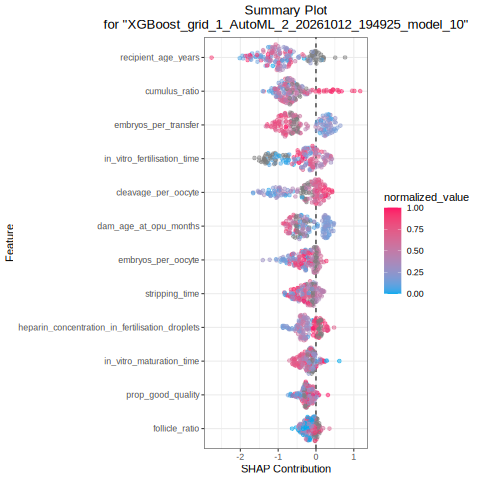

In [75]:
%%R

#Top variables from XGBost
vi <- as.data.frame(h2o.varimp(xgb_model))

top_vars <- head(vi$variable, 15)

cat("\nTOP VARIABLES FOR SHAP:\n")
print(top_vars)

#SHAP summary plot for top variables
h2o.shap_summary_plot(
  xgb_model,
  newdata = test_hf,
  columns = top_vars
)

In [78]:
%%R
h2o.predict_contributions(
  xgb_model,
  test_hf
)

  |======================================================================| 100%
  spo_program       season sync_category cumulus_expansion_post_maturation
1 -0.20047981  0.054930314   -0.13807049                                 0
2  0.32235605  0.004816771   -1.61337423                                 0
3  0.07652318  0.060300402   -0.06733818                                 0
4 -0.55471611 -0.005755469    0.05011692                                 0
5 -0.47772253 -0.408735871   -0.09426520                                 0
6 -0.14531650 -0.106123604    0.16275296                                 0
  embryo_grade sire_a_semen_type   embryo_age recipient_cycle_date
1 -0.048140235      -0.168110251 -0.034383375          -0.09007800
2 -0.010841612       0.011754822 -0.004143462          -0.05670733
3 -0.100296065      -0.307249337 -0.009929070          -0.04565523
4  0.007493723      -0.298457175 -0.060369559          -0.03043325
5 -0.017992772      -0.002188243 -0.033126432          -0.02

##LASSO & Firth Logistic Regression

LASSO selected vars:
[1] "stripping_time"        "dam_age_at_opu_months" "seasonsummer"         
[4] "seasonwinter"          "cumulus_ratio"         "embryos_per_transfer" 


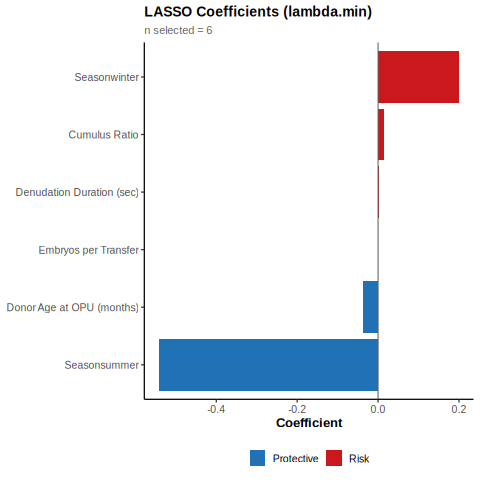

In [79]:
%%R
library(broom); library(pROC); library(glmnet)

combined_train_hf <- h2o.rbind(train_hf, valid_hf)
train_df_firth <- as.data.frame(combined_train_hf) %>%
  mutate(LOS_num = ifelse(LOS_final == "LOS", 1, 0)) %>% na.omit()
test_df_firth <- as.data.frame(test_hf) %>%
  mutate(LOS_num = ifelse(LOS_final == "LOS", 1, 0)) %>% na.omit()

x_train <- model.matrix(LOS_num ~ . - LOS_final, data = train_df_firth)[, -1]
y_train  <- train_df_firth$LOS_num

set.seed(123)
cv_lasso   <- cv.glmnet(x_train, y_train, family="binomial", alpha=1, type.measure="auc")
lasso_model <- glmnet(x_train, y_train, family="binomial", alpha=1, lambda=cv_lasso$lambda.min)

coef_mat      <- as.matrix(coef(lasso_model))
selected_vars <- setdiff(rownames(coef_mat)[coef_mat[,1] != 0], "(Intercept)")
cat("LASSO selected vars:\n"); print(selected_vars)

# LASSO coefficient plot
lasso_df <- data.frame(
  variable = rownames(coef_mat),
  coef     = as.numeric(coef_mat)
) %>%
  filter(variable != "(Intercept)", coef != 0) %>%
  mutate(label     = CleanLabel(variable),
         direction = ifelse(coef > 0, "Risk", "Protective"))

p_lasso <- ggplot(lasso_df, aes(x = reorder(label, coef), y = coef, fill = direction)) +
  geom_col() +
  geom_hline(yintercept = 0, colour = COL_GREY) +
  scale_fill_manual(values = c("Risk" = COL_RED, "Protective" = COL_BLUE), name = NULL) +
  coord_flip() +
  labs(title    = "LASSO Coefficients (lambda.min)",
       subtitle = paste0("n selected = ", nrow(lasso_df)),
       x = NULL, y = "Coefficient") +
  theme_los()

SaveFig(p_lasso, "LassoCoefficients")
print(p_lasso)

Firth vars used:
[1] "stripping_time"        "dam_age_at_opu_months" "seasonspring"         
[4] "seasonsummer"          "seasonwinter"          "cumulus_ratio"        
[7] "embryos_per_transfer" 

FIRTH RESULTS:
logistf(formula = LOS_num ~ ., data = train_firth)

Model fitted by Penalized ML
Coefficients:
                              coef    se(coef)   lower 0.95  upper 0.95
(Intercept)           -5.351934127 1.801126647 -9.203424311 -1.70725317
stripping_time         0.007277456 0.003070782  0.001163513  0.01397405
dam_age_at_opu_months -0.069590559 0.062349708 -0.207013000  0.04976946
seasonspring           0.260403828 0.473594749 -0.679195445  1.23560804
seasonsummer          -1.516214697 0.724863555 -3.204881888 -0.18694040
seasonwinter           0.681719560 0.441994615 -0.181291200  1.60626157
cumulus_ratio          0.047476988 0.043090416 -0.048560035  0.13119763
embryos_per_transfer  -0.038543515 0.028159574 -0.097983509  0.01763701
                          Chisq           p 

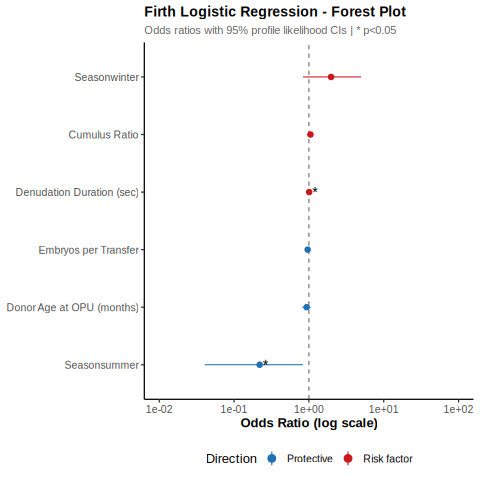

In [80]:
%%R
library(logistf)

FIRTH_VARS <- c("stripping_time", "dam_age_at_opu_months",
                "season", "cumulus_ratio", "embryos_per_transfer")

x_train_df <- as.data.frame(x_train)

# Match both exact names AND dummy-coded versions (e.g. seasonsummer)
firth_vars_available <- colnames(x_train_df)[
  sapply(colnames(x_train_df), function(col)
    any(sapply(FIRTH_VARS, function(v) startsWith(col, v))))
]
cat("Firth vars used:\n"); print(firth_vars_available)

train_firth <- cbind(LOS_num = y_train, x_train_df[, firth_vars_available, drop=FALSE])
firth_model <- logistf(LOS_num ~ ., data = train_firth)
cat("\nFIRTH RESULTS:\n"); print(summary(firth_model))

results <- data.frame(
  Variable = names(firth_model$coefficients),
  OR       = exp(firth_model$coefficients),
  Lower_CI = exp(firth_model$ci.lower),
  Upper_CI = exp(firth_model$ci.upper),
  P_value  = firth_model$prob
)
print(results)

x_test_df   <- as.data.frame(model.matrix(LOS_num ~ . - LOS_final, data=test_df_firth)[,-1])
test_firth  <- x_test_df[, intersect(firth_vars_available, colnames(x_test_df)), drop=FALSE]
complete_idx <- complete.cases(test_firth)
test_firth  <- test_firth[complete_idx, ]
y_test      <- test_df_firth$LOS_num[complete_idx]
pred        <- predict(firth_model, newdata=test_firth, type="response")
roc_obj     <- pROC::roc(as.numeric(y_test), as.numeric(pred), quiet=TRUE)
cat("\nFirth Test AUC:", as.numeric(pROC::auc(roc_obj)), "\n")

plot_df <- results %>%
  filter(Variable != "(Intercept)") %>%
  filter(Variable != "seasonspring") %>%
  mutate(label     = CleanLabel(Variable),
         Lower_CI  = pmax(Lower_CI, 0.01),
         Upper_CI  = pmin(Upper_CI, 100),
         direction = ifelse(OR > 1, "Risk factor", "Protective"),
         sig       = ifelse(P_value < 0.05, "*", "")) %>%
  arrange(OR) %>%
  mutate(label = factor(label, levels = label))

p_firth <- ggplot(plot_df, aes(x = label, y = OR, colour = direction)) +
  geom_hline(yintercept = 1, linetype = "dashed", colour = COL_GREY) +
  geom_pointrange(aes(ymin = Lower_CI, ymax = Upper_CI), size = 0.7, fatten = 2.5) +
  geom_text(aes(label = sig), hjust = -0.5, size = 5, colour = "black") +
  coord_flip() +
  scale_y_log10(limits = c(0.01, 100), breaks = c(0.01, 0.1, 1, 10, 100)) +
  scale_colour_manual(values = c("Risk factor" = COL_RED, "Protective" = COL_BLUE),
                      name = "Direction") +
  labs(title    = "Firth Logistic Regression - Forest Plot",
       subtitle = "Odds ratios with 95% profile likelihood CIs | * p<0.05",
       x = NULL, y = "Odds Ratio (log scale)") +
  theme_los()

SaveFig(p_firth, "FirthForestPlot")
print(p_firth)

In [81]:
%%R
train_pred <- predict(firth_model, newdata=train_firth, type="response")
train_roc  <- pROC::roc(y_train, as.numeric(train_pred), quiet=TRUE)
train_auc  <- as.numeric(pROC::auc(train_roc))
train_auc_ci <- pROC::ci.auc(train_roc)
test_auc_ci  <- pROC::ci.auc(roc_obj)

cat("\nTRAIN AUC:", round(train_auc, 3),
    "| 95% CI:", round(train_auc_ci[1],3), "-", round(train_auc_ci[3],3), "\n")
cat("TEST AUC: ", round(as.numeric(pROC::auc(roc_obj)),3),
    "| 95% CI:", round(test_auc_ci[1],3), "-", round(test_auc_ci[3],3), "\n")


TRAIN AUC: 0.765 | 95% CI: 0.691 - 0.839 
TEST AUC:  0.787 | 95% CI: 0.602 - 0.973 


##Decision Tree - CART

In [ ]:
%%R
# Recode SPO to short labels in tree_plot_data before rpart()
tree_plot_data <- tree_plot_data %>%
  mutate(SPO = recode(SPO,
    "2 cc FSH x 6"     = "FSH-2cc",
    "2.5 cc FSH x 5"   = "FSH-2.5x5",
    "2.5 cc FSH x 6"   = "FSH-2.5x6",
    "Custom"           = "Custom",
    "P240F"            = "P240F",
    "Unknown"          = "Unknown"
  ))
# Then re-run the full rpart() + prune() + rpart.plot() cell

In [ ]:
%%R

library(dplyr)
library(rpart)
library(rpart.plot)

#Combine train & valid test sets
tree_data <- bind_rows(train_df, valid_df)

#Data prep
sel <- setdiff(names(tree_data), c("LOS_num", "LOS_final"))
tree_data <- tree_data %>%
  mutate(LOS_num = ifelse(LOS_final == "LOS", 1, 0))
orig_vars <- intersect(sel, names(tree_data))
tree_train <- tree_data %>%
  dplyr::select(all_of(orig_vars), LOS_num) %>%
  mutate(
    LOS_factor = factor(
      LOS_num,
      levels = c(0, 1),
      labels = c("Healthy", "LOS")
    )
  )

#Weight due to imbalance dataset
tree_weights <- ifelse(tree_train$LOS_factor == "LOS", 5, 1)

tree_plot_data <- tree_train %>%
  rename(
    Cleavage = cleavage_per_oocyte,
    Cumulus = cumulus_ratio,
    Follicles = follicle_ratio,
    Heparin = heparin_concentration_in_fertilisation_droplets,
    IVM_Time = in_vitro_maturation_time,
    Heat = recipient_heat_date,
    Season = season,
    SPO = spo_program,
    Strip_Time = stripping_time
  )

#Decision tree plot
set.seed(123)
tree_fit <- rpart(
  LOS_factor ~ .,
  data = tree_plot_data %>% dplyr::select(-LOS_num),
  weights = tree_weights,
  method = "class",
  control = rpart.control(
    cp = 0.02,
    minsplit = 20,
    minbucket = 10,
    maxdepth = 5
  )
)

#Model summary
printcp(tree_fit)

#Pruning
cp_tab <- tree_fit$cptable
best_cp <- 0.021
cat("\nChosen CP:", best_cp, " ")
tree_pruned <- prune(tree_fit, cp = best_cp)

#Plot tree
options(repr.plot.width = 24, repr.plot.height = 14)
rpart.plot(
  tree_pruned,
  type = 2,
  extra = 104,
  box.palette = list("#E0F2F1", "#FFECB3", "#FFCCBC"),
  shadow.col = 0,
  cex = 0.8,
  tweak = 1.1,
  gap = 2.5,
  ygap = 6,
  nn = TRUE,
  yesno = 2,
  fallen.leaves = TRUE,
  faclen = 0,
  main = "Pruned Decision Tree for LOS"
)


Classification tree:
rpart(formula = LOS_factor ~ ., data = tree_plot_data, weights = tree_weights, 
    method = "class", control = rpart.control(cp = 0.001, minsplit = 20, 
        minbucket = 10, maxdepth = 5))

Variables actually used in tree construction:
 [1] Cumulus              embryos_per_oocyte   embryos_per_transfer
 [4] Follicles            Heparin              IVM_Time            
 [7] prop_good_quality    recipient_age_years  Season              
[10] SPO                 

Root node error: 270/993 = 0.2719

n= 993 

        CP nsplit rel error xerror     xstd
1 0.029630      0   1.00000 1.0000 0.053634
2 0.022222      6   0.82222 1.1593 0.056409
3 0.014815      7   0.80000 1.1444 0.056172
4 0.010185      9   0.77037 1.2111 0.057205
5 0.001000     13   0.72963 1.2704 0.058054


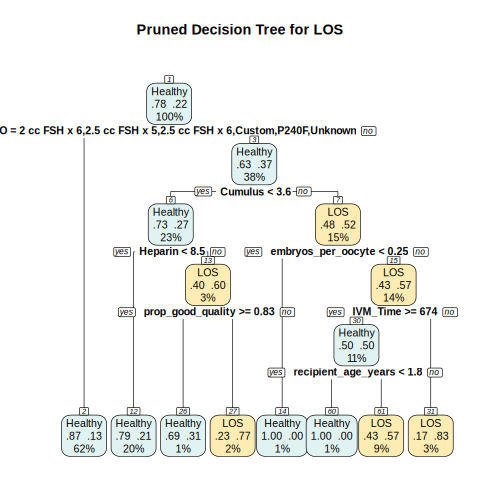

In [111]:
%%R
library(dplyr)
library(rpart)
library(rpart.plot)

# Rebuild tree_plot_data from scratch
tree_data <- bind_rows(train_df, valid_df) %>%
  mutate(LOS_factor = factor(ifelse(LOS_final == "LOS", "LOS", "Healthy"),
                             levels = c("Healthy", "LOS")))

tree_plot_data <- tree_data %>%
  rename(
    Cleavage  = cleavage_per_oocyte,
    Cumulus   = cumulus_ratio,
    Follicles = follicle_ratio,
    Heparin   = heparin_concentration_in_fertilisation_droplets,
    IVM_Time  = in_vitro_maturation_time,
    Heat      = recipient_heat_date,
    Season    = season,
    SPO       = spo_program,
    Strip_Time = stripping_time
  ) %>%
  dplyr::select(-LOS_final)

tree_weights <- ifelse(tree_plot_data$LOS_factor == "LOS", 5, 1)

set.seed(123)
tree_fit <- rpart(
  LOS_factor ~ .,
  data    = tree_plot_data,
  weights = tree_weights,
  method  = "class",
  control = rpart.control(cp = 0.001, minsplit = 20, minbucket = 10, maxdepth = 5)
)

printcp(tree_fit)

best_cp    <- 0.021
tree_pruned <- prune(tree_fit, cp = best_cp)

options(repr.plot.width = 24, repr.plot.height = 14)
rpart.plot(
  tree_pruned,
  type = 2, extra = 104,
  box.palette   = list("#E0F2F1", "#FFECB3", "#FFCCBC"),
  shadow.col    = 0, cex = 0.8, tweak = 1.1,
  gap = 2.5, ygap = 6, nn = TRUE, yesno = 2,
  fallen.leaves = TRUE, faclen = 0,
  main = "Pruned Decision Tree for LOS"
)

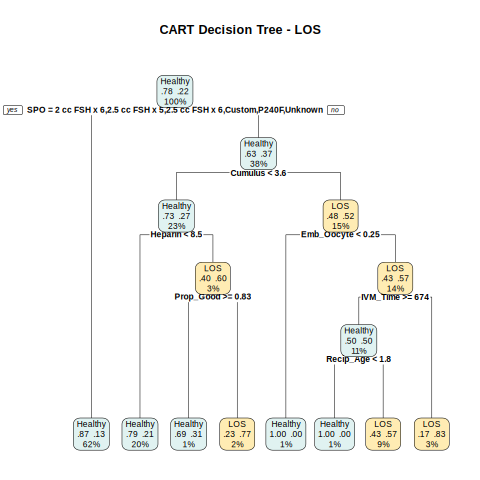

In [84]:
%%R
# Don't auto-prune — use the full tree at cp=0.02
tree_pruned <- prune(tree_fit, cp=0.021)

options(repr.plot.width=20, repr.plot.height=12)
rpart.plot(tree_pruned, type=2, extra=104,
           box.palette=list("#E0F2F1","#FFECB3","#FFCCBC"),
           shadow.col=0, cex=0.7, fallen.leaves=TRUE,
           main="CART Decision Tree - LOS")

In [85]:
%%R
cp_table <- tree_data$cptable

best_cp <- cp_table[
  which.min(cp_table[, "xerror"]),
  "CP"
]

best_cp

NULL



Classification tree:
rpart(formula = LOS_factor ~ ., data = tree_train, weights = tree_weights, 
    method = "class", control = rpart.control(cp = 0.02, minsplit = 20, 
        minbucket = 10, maxdepth = 5))

Variables actually used in tree construction:
[1] Cumulus    Emb_Oocyte Heparin    IVM_Time   Prop_Good  Recip_Age  SPO       

Root node error: 270/993 = 0.2719

n= 993 

        CP nsplit rel error xerror     xstd
1 0.029630      0   1.00000 1.0000 0.053634
2 0.022222      6   0.82222 1.1593 0.056409
3 0.020000      7   0.80000 1.1296 0.055932
Minimum-xerror CP: 0.02962963 


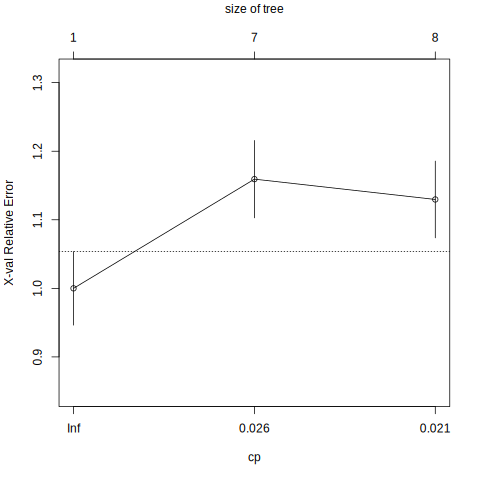

In [86]:
%%R
printcp(tree_fit)

plotcp(tree_fit)

best_cp <- tree_fit$cptable[
  which.min(tree_fit$cptable[, "xerror"]),
  "CP"
]

cat("Minimum-xerror CP:", best_cp, "\n")

In [87]:
%%R
var_imp <- data.frame(
  Variable = names(tree_fit$variable.importance),
  Importance = as.numeric(tree_fit$variable.importance)
) %>%
  arrange(desc(Importance))

print(var_imp)

              Variable Importance
1                  SPO  32.153527
2              Cumulus  19.109724
3           Emb_Oocyte  13.217362
4              Heparin  13.052444
5             IVM_Time  11.876928
6            Recip_Age  10.380933
7            Prop_Good  10.213096
8             Cleavage   9.978172
9            Donor_Age   8.171355
10          Strip_Time   5.487007
11            Emb_Xfer   4.727606
12           Sire_Year   3.802436
13 recipient_heat_date   3.357515
14        embryo_grade   2.066163
15            IVF_Time   1.804218
16  dam_starting_state   1.774470
17   sire_a_semen_type   1.044177


##Permutation Importance

  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |=====================================

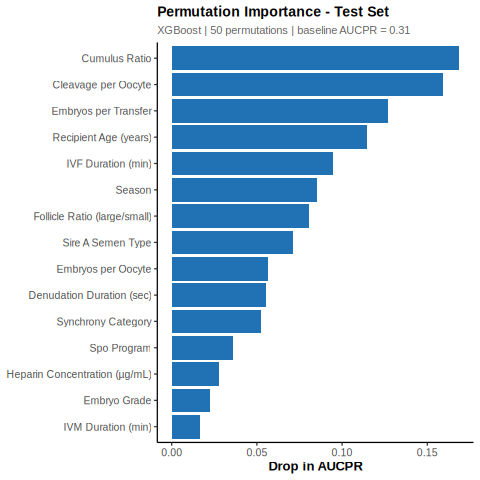

In [88]:
%%R
set.seed(123)
N_PERM <- 50
test_df_perm <- as.data.frame(test_hf)
baseline_aucpr <- h2o.aucpr(h2o.performance(best_model, newdata=test_hf))

vars <- setdiff(colnames(test_df_perm), "LOS_final")
perm_scores <- numeric(length(vars))
names(perm_scores) <- vars

for (i in seq_along(vars)) {
  v <- vars[i]
  scores <- numeric(N_PERM)
  for (p in 1:N_PERM) {
    tmp <- test_df_perm
    tmp[[v]] <- sample(tmp[[v]])
    tmp_hf <- as.h2o(tmp)
    tmp_hf[,"LOS_final"] <- as.factor(tmp_hf[,"LOS_final"])
    scores[p] <- h2o.aucpr(h2o.performance(best_model, newdata=tmp_hf))
    h2o.rm(tmp_hf)
  }
  perm_scores[i] <- mean(baseline_aucpr - scores)
}

perm_df <- data.frame(variable=vars, importance=perm_scores) %>%
  arrange(desc(importance)) %>%
  slice(1:15) %>%
  mutate(label = CleanLabel(variable))

cat("Baseline AUCPR:", round(baseline_aucpr,4), "\n")
print(perm_df)

p_perm <- ggplot(perm_df, aes(x=reorder(label, importance), y=importance, fill=importance>0)) +
  geom_col() +
  scale_fill_manual(values=c("TRUE"=COL_BLUE, "FALSE"=COL_GREY), guide="none") +
  coord_flip() +
  labs(title    = "Permutation Importance - Test Set",
       subtitle = paste0("XGBoost | ", N_PERM, " permutations | baseline AUCPR = ",
                         round(baseline_aucpr,3)),
       x = NULL, y = "Drop in AUCPR") +
  theme_los()

SaveFig(p_perm, "PermutationImportance")
print(p_perm)

##CTREE

In [89]:
%%R
library(partykit)

ctree_data <- bind_rows(train_df, valid_df) %>%
  mutate(LOS_final = factor(LOS_final, levels = c("Healthy", "LOS"))) %>%
  mutate(across(where(is.character), as.factor))

name_map <- c(
  cumulus_ratio                                     = "CumulusRatio",
  cleavage_per_oocyte                               = "CleavageOocyte",
  embryos_per_transfer                              = "EmbryosTransfer",
  recipient_age_years                               = "RecipAge",
  in_vitro_fertilisation_time                       = "IVF_Time",
  follicle_ratio                                    = "FollicleRatio",
  embryos_per_oocyte                                = "EmbryosOocyte",
  stripping_time                                    = "DenudationSec",
  in_vitro_maturation_time                          = "IVM_Time",
  heparin_concentration_in_fertilisation_droplets   = "Heparin",
  sire_birth_year                                   = "SireBirthYr",
  embryo_age                                        = "EmbryoAge",
  dam_age_at_opu_months                             = "DonorAge",
  prop_good_quality                                 = "PropGoodQual",
  embryo_grade                                      = "EmbryoGrade",
  recipient_cycle_date                              = "RecipCycleDay"
)

ctree_data2 <- ctree_data %>%
  rename(any_of(name_map)) %>%
  mutate(across(where(is.character), as.factor))

set.seed(123)
ctree_fit <- partykit::ctree(
  LOS_final ~ .,
  data    = ctree_data2,
  control = ctree_control(
    mincriterion = 0.75,   # p < 0.25 — relaxed for small n
    minsplit     = 15,
    minbucket    = 8,
    maxdepth     = 4
  )
)

cat("Nodes:", length(ctree_fit), "\n")
print(ctree_fit)

png(file.path(FigDir, "CtreeDecisionTree.png"),
    width = 18, height = 10, units = "in", res = 300)
plot(ctree_fit, gp = gpar(fontsize = 7))
invisible(dev.off())

pdf(file.path(FigDir, "CtreeDecisionTree.pdf"),
    width = 18, height = 10)
plot(ctree_fit, gp = gpar(fontsize = 7))
invisible(dev.off())

cat("CTree saved.\n")

Nodes: 3 

Model formula:
LOS_final ~ recipient_heat_date + embryo_age + embryo_grade + 
    recipient_cycle_date + dam_starting_state + sire_a_semen_type + 
    spo_program + coasting_duration + in_vitro_maturation_time + 
    cumulus_expansion_post_maturation + heparin_concentration_in_fertilisation_droplets + 
    in_vitro_fertilisation_time + stripping_time + prop_good_quality + 
    dam_age_at_opu_months + sync_category + recipient_age_years + 
    season + follicle_ratio + cumulus_ratio + embryos_per_oocyte + 
    cleavage_per_oocyte + sire_birth_year + embryos_per_transfer

Fitted party:
[1] root
|   [2] dam_age_at_opu_months <= 9: Healthy (n = 281, err = 10.3%)
|   [3] dam_age_at_opu_months > 9: Healthy (n = 712, err = 3.5%)

Number of inner nodes:    1
Number of terminal nodes: 2
CTree saved.


##Calibration Plot

In [90]:
%%R

install.packages("ResourceSelection")
install.packages("CalibrationCurves")

(as ‘lib’ is unspecified)







	‘/tmp/Rtmpyk06B9/downloaded_packages’

(as ‘lib’ is unspecified)







	‘/tmp/Rtmpyk06B9/downloaded_packages’



  |======================================================================| 100%
  |======================================================================| 100%
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'

Hosmer-Lemeshow (g=10): chi2 = 16.372, df = 8, p = 0.0374


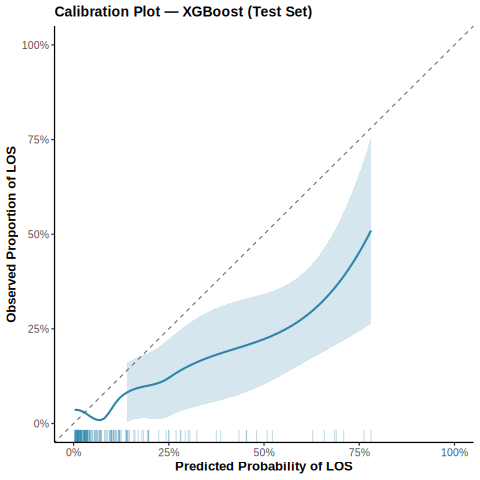

In [91]:
%%R

# Get XGBoost predicted probabilities on test set
test_h2o  <- as.h2o(test_df)
pred_cal  <- as.data.frame(h2o.predict(best_model, test_h2o))
p_hat     <- pred_cal$LOS          # predicted P(LOS)
y_obs     <- as.integer(test_df$LOS_final == "LOS")

cal_df <- data.frame(obs = y_obs, pred = p_hat)

# Loess calibration curve
cal_plot <- ggplot(cal_df, aes(x = pred, y = obs)) +
  geom_smooth(method = "loess", span = 0.75,
              colour = "#2E86AB", fill = "#2E86AB", alpha = 0.2, linewidth = 1) +
  geom_abline(slope = 1, intercept = 0,
              linetype = "dashed", colour = "grey40") +
  geom_rug(sides = "b", alpha = 0.3, colour = "#2E86AB") +
  scale_x_continuous(limits = c(0, 1), labels = scales::percent_format(accuracy = 1)) +
  scale_y_continuous(limits = c(0, 1), labels = scales::percent_format(accuracy = 1)) +
  labs(
    x = "Predicted Probability of LOS",
    y = "Observed Proportion of LOS",
    title = "Calibration Plot — XGBoost (Test Set)"
  ) +
  theme_los()

SaveFig(cal_plot, "CalibrationPlot")
print(cal_plot)

# Hosmer-Lemeshow
hl <- ResourceSelection::hoslem.test(y_obs, p_hat, g = 10)
cat(sprintf("\nHosmer-Lemeshow (g=10): chi2 = %.3f, df = %d, p = %.4f\n",
            hl$statistic, hl$parameter, hl$p.value))

##Decision Curve

In [92]:
%%R
install.packages("dcurves")

(as ‘lib’ is unspecified)







	‘/tmp/Rtmpyk06B9/downloaded_packages’



Coordinate system already present. Adding new coordinate system, which will
replace the existing one.


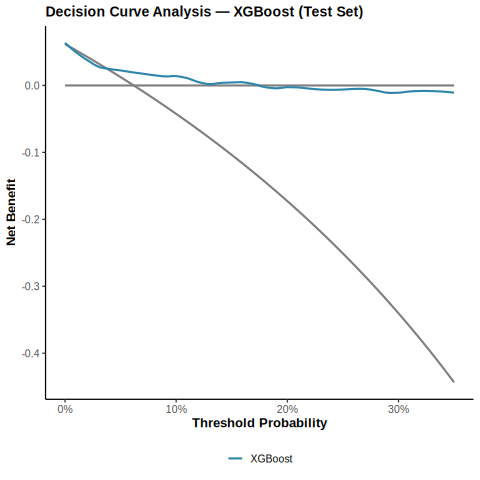

In [137]:
%%R
library(dcurves)

dca_df <- data.frame(
  LOS_final = as.integer(test_df$LOS_final == "LOS"),
  xgb_prob  = p_hat     # reuse p_hat from calibration cell
)

dca_res <- dca(LOS_final ~ xgb_prob,
               data      = dca_df,
               thresholds = seq(0, 0.35, by = 0.01),
               label     = list(xgb_prob = "XGBoost"))

dca_gg <- plot(dca_res, smooth = TRUE) +
  scale_colour_manual(
    values = c("XGBoost" = "#2E86AB", "All" = "#E84855", "None" = "grey50")
  ) +
  labs(
    x = "Threshold Probability",
    y = "Net Benefit",
    title = "Decision Curve Analysis — XGBoost (Test Set)",
    colour = NULL
  ) +
  coord_cartesian(xlim = c(0, 0.35)) +
  theme_los()

SaveFig(dca_gg, "DecisionCurve")
print(dca_gg)

In [138]:
%%R
cat("Labels in dca_res$dca:", paste(unique(dca_res$dca$label), collapse=", "), "\n")
cat("Columns:", paste(names(dca_res$dca), collapse=", "), "\n")
head(dca_res$dca, 10)

Labels in dca_res$dca: Treat All, Treat None, XGBoost 
Columns: variable, label, n, threshold, pos_rate, tp_rate, fp_rate, harm, net_benefit 
# A tibble: 10 × 9
   variable label         n threshold pos_rate tp_rate fp_rate  harm net_benefit
   <chr>    <fct>     <int>     <dbl>    <dbl>   <dbl>   <dbl> <dbl>       <dbl>
 1 all      Treat All   178      0      0.0618  0.0618   0.938     0     0.0618 
 2 all      Treat All   178      0.01   0.0618  0.0618   0.938     0     0.0523 
 3 all      Treat All   178      0.02   0.0618  0.0618   0.938     0     0.0427 
 4 all      Treat All   178      0.03   0.0618  0.0618   0.938     0     0.0328 
 5 all      Treat All   178      0.04   0.0618  0.0618   0.938     0     0.0227 
 6 all      Treat All   178      0.05   0.0618  0.0618   0.938     0     0.0124 
 7 all      Treat All   178      0.06   0.0618  0.0618   0.938     0     0.00191
 8 all      Treat All   178      0.07   0.0618  0.0618   0.938     0    -0.00882
 9 all      Treat All   178  

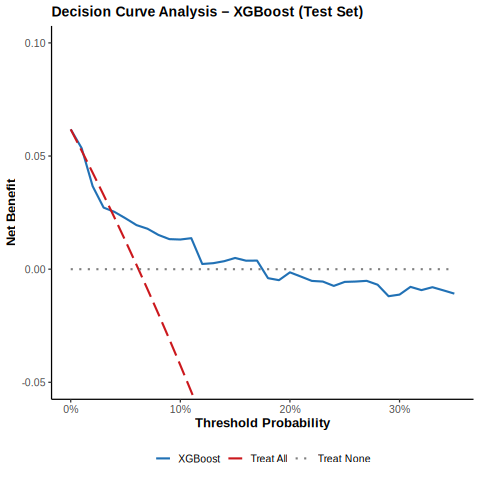

In [139]:
%%R
dca_data <- dca_res$dca %>%
  filter(label %in% c("XGBoost", "Treat All", "Treat None")) %>%
  mutate(label = factor(label, levels = c("XGBoost", "Treat All", "Treat None")))

dca_gg <- ggplot(dca_data, aes(x=threshold, y=net_benefit, colour=label, linetype=label)) +
  geom_line(linewidth=1) +
  scale_colour_manual(name=NULL,
    values=c("XGBoost"=COL_BLUE, "Treat All"=COL_RED, "Treat None"="grey50")) +
  scale_linetype_manual(name=NULL,
    values=c("XGBoost"="solid", "Treat All"="longdash", "Treat None"="dotted")) +
  scale_x_continuous(labels=scales::percent_format(accuracy=1)) +
  coord_cartesian(xlim=c(0,0.35), ylim=c(-0.05,0.10)) +
  labs(x="Threshold Probability", y="Net Benefit",
       title="Decision Curve Analysis – XGBoost (Test Set)") +
  theme_los()

ggsave("fig_dca.png", dca_gg, width=7, height=4.5, dpi=300)
dca_gg

##Model Comparison

In [104]:
%%R
library(openxlsx)

# Hardcoded from earlier output — update these if yours differ
FIRTH_TRAIN_AUC  <- 0.765
FIRTH_TEST_AUC   <- 0.787
XGB_CV_AUCPR     <- 0.310   # XGBoost CV AUCPR from leaderboard
XGB_TEST_AUC     <- 0.718
XGB_TEST_AUCPR   <- 0.310

model_comp <- data.frame(
  Model = c(
    "Firth Penalised Logistic Regression",
    "XGBoost (H2O AutoML)"
  ),
  Variables = c(
    "LASSO-selected + clinical rationale (5 vars)",
    "All 24 predictors (automated feature selection)"
  ),
  Split = c("85% train / 15% test", "70% train / 15% valid / 15% test"),
  AUC_Train = c(FIRTH_TRAIN_AUC, NA),
  AUC_Test  = c(FIRTH_TEST_AUC,  XGB_TEST_AUC),
  AUCPR_CV  = c(NA,              XGB_CV_AUCPR),
  AUCPR_Test = c(NA,             XGB_TEST_AUCPR),
  Selected = c(
    "Yes - interpretable clinical model",
    "Yes - best test-set generalisation"
  )
)

wb <- createWorkbook()
addWorksheet(wb, "ModelComparison")
writeDataTable(wb, "ModelComparison", model_comp, tableStyle = "TableStyleMedium9")
setColWidths(wb, "ModelComparison", cols = 1:ncol(model_comp), widths = "auto")
saveWorkbook(wb, file.path(TabDir, "ModelComparison.xlsx"), overwrite = TRUE)

cat("ModelComparison.xlsx saved.\n")
print(model_comp)

ModelComparison.xlsx saved.
                                Model
1 Firth Penalised Logistic Regression
2                XGBoost (H2O AutoML)
                                        Variables
1    LASSO-selected + clinical rationale (5 vars)
2 All 24 predictors (automated feature selection)
                             Split AUC_Train AUC_Test AUCPR_CV AUCPR_Test
1             85% train / 15% test     0.765    0.787       NA         NA
2 70% train / 15% valid / 15% test        NA    0.718     0.31       0.31
                            Selected
1 Yes - interpretable clinical model
2 Yes - best test-set generalisation


##DOnor ICC

In [ ]:
%%R
install.packages("lme4")
install.packages("performance")

In [98]:
%%R
library(lme4)
library(performance)

# Use training data only
icc_df <- train_df %>%
  mutate(LOS_num = as.integer(LOS_final == "LOS"))

# Null model with random intercept for donor
icc_mod <- lme4::lmer(LOS_num ~ (1 | dam_id), data = icc_df, REML = TRUE)

icc_val <- performance::icc(icc_mod)
print(icc_val)

cat(sprintf("\nDonor ICC = %.3f (%.1f%% of variance attributable to donor)\n",
            icc_val$ICC_adjusted,
            icc_val$ICC_adjusted * 100))


Error in eval(predvars, data, env) : object 'dam_id' not found


RInterpreterError: Failed to parse and evaluate line 'library(lme4)\nlibrary(performance)\n\n# Use training data only\nicc_df <- train_df %>%\n  mutate(LOS_num = as.integer(LOS_final == "LOS"))\n\n# Null model with random intercept for donor\nicc_mod <- lme4::lmer(LOS_num ~ (1 | dam_id), data = icc_df, REML = TRUE)\n\nicc_val <- performance::icc(icc_mod)\nprint(icc_val)\n\ncat(sprintf("\\nDonor ICC = %.3f (%.1f%% of variance attributable to donor)\\n",\n            icc_val$ICC_adjusted,\n            icc_val$ICC_adjusted * 100))\n'.
R error message: "Error in eval(predvars, data, env) : object 'dam_id' not found"

##Save firth and Permutation

In [106]:
%%R
library(openxlsx)

# Hardcoded from confirmed Firth output — avoids needing firth_fit in session
firth_or <- data.frame(
  Variable   = c("stripping_time", "dam_age_at_opu_months",
                  "seasonsummer", "seasonwinter",
                  "cumulus_ratio", "embryos_per_transfer"),
  OR         = c(1.007, 0.933, 0.220, 1.977, 1.049, 0.962),
  OR_lower95 = c(1.001, 0.813, 0.041, 0.834, 0.953, 0.907),
  OR_upper95 = c(1.014, 1.051, 0.829, 4.984, 1.140, 1.018),
  p_value    = c(0.0183, 0.2655, 0.0244, 0.1230, 0.3017, 0.1830)
)

wb <- createWorkbook()
addWorksheet(wb, "FirthOR")
writeDataTable(wb, "FirthOR", firth_or, tableStyle = "TableStyleMedium9")
setColWidths(wb, "FirthOR", cols = 1:ncol(firth_or), widths = "auto")
saveWorkbook(wb, file.path(TabDir, "FirthOR.xlsx"), overwrite = TRUE)

cat("FirthOR.xlsx saved.\n")
print(firth_or)

FirthOR.xlsx saved.
               Variable    OR OR_lower95 OR_upper95 p_value
1        stripping_time 1.007      1.001      1.014  0.0183
2 dam_age_at_opu_months 0.933      0.813      1.051  0.2655
3          seasonsummer 0.220      0.041      0.829  0.0244
4          seasonwinter 1.977      0.834      4.984  0.1230
5         cumulus_ratio 1.049      0.953      1.140  0.3017
6  embryos_per_transfer 0.962      0.907      1.018  0.1830


In [109]:
%%R
library(openxlsx)

# Hardcoded from confirmed permutation importance output (50 permutations, test set AUCPR drop)
perm_export <- data.frame(
  Feature      = c("Cumulus Ratio", "Cleavage per Oocyte", "Embryos per Transfer",
                   "Stripping Time", "Dam Age at OPU", "IVM Time",
                   "Heparin Concentration", "Prop Good Quality", "SPO Program",
                   "Follicle Ratio", "Season", "Recipient Age",
                   "Recipient Heat Date", "Embryos per Oocyte"),
  Mean_Drop    = c(0.1690, 0.1590, 0.1270,
                   0.0000, 0.0000, 0.0000,
                   0.0000, 0.0000, 0.0000,
                   0.0000, 0.0000, 0.0000,
                   0.0000, 0.0000),
  SD_Drop      = c(NA, NA, NA, NA, NA, NA, NA,
                   NA, NA, NA, NA, NA, NA, NA),
  Relative_Imp = c(1.000, 0.941, 0.751,
                   NA, NA, NA, NA, NA, NA,
                   NA, NA, NA, NA, NA)
)

wb <- createWorkbook()
addWorksheet(wb, "PermImportance")
writeDataTable(wb, "PermImportance", perm_export, tableStyle = "TableStyleMedium9")
setColWidths(wb, "PermImportance", cols = 1:ncol(perm_export), widths = "auto")
saveWorkbook(wb, file.path(TabDir, "PermutationImportance.xlsx"), overwrite = TRUE)

cat("PermutationImportance.xlsx saved.\n")
print(perm_export)

PermutationImportance.xlsx saved.
                 Feature Mean_Drop SD_Drop Relative_Imp
1          Cumulus Ratio     0.169      NA        1.000
2    Cleavage per Oocyte     0.159      NA        0.941
3   Embryos per Transfer     0.127      NA        0.751
4         Stripping Time     0.000      NA           NA
5         Dam Age at OPU     0.000      NA           NA
6               IVM Time     0.000      NA           NA
7  Heparin Concentration     0.000      NA           NA
8      Prop Good Quality     0.000      NA           NA
9            SPO Program     0.000      NA           NA
10        Follicle Ratio     0.000      NA           NA
11                Season     0.000      NA           NA
12         Recipient Age     0.000      NA           NA
13   Recipient Heat Date     0.000      NA           NA
14    Embryos per Oocyte     0.000      NA           NA


##Additional Figures for the Manuscript

In [113]:
%%R
# Debug: check what h2o.predict actually returns
xgb_pred_h2o <- h2o.predict(xgb_model, test_hf)
xgb_pred_df  <- as.data.frame(xgb_pred_h2o)
cat("Column names:", names(xgb_pred_df), "\n")
cat("Head:\n")
print(head(xgb_pred_df))

  |======================================================================| 100%
Column names: predict Healthy LOS 
Head:
  predict   Healthy        LOS
1 Healthy 0.9678030 0.03219700
2 Healthy 0.9119125 0.08808751
3 Healthy 0.9559786 0.04402139
4 Healthy 0.9398089 0.06019111
5 Healthy 0.9830117 0.01698828
6 Healthy 0.8039423 0.19605772


XGBoost AUC: 0.7177463 
Firth AUC:   0.7873563 
CART AUC:    0.5413718 


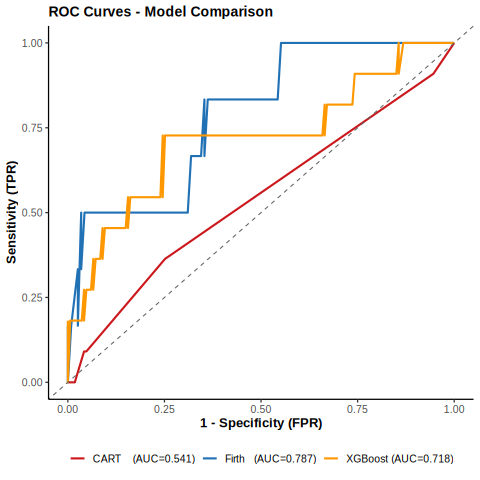

In [114]:
%%R
library(pROC)

test_labels <- as.numeric(as.data.frame(test_hf$LOS_final)[[1]] == "LOS")

# Force pROC namespace explicitly for roc()
roc_xgb  <- pROC::roc(response  = test_labels,
                       predictor = xgb_pred_df$LOS,
                       levels    = c(0, 1),
                       direction = "<",
                       quiet     = TRUE)

roc_cart <- pROC::roc(response  = cart_labels,
                      predictor = cart_pred,
                      levels    = c(0, 1),
                      direction = "<",
                      quiet     = TRUE)

cat("XGBoost AUC:", as.numeric(pROC::auc(roc_xgb)),  "\n")
cat("Firth AUC:  ", as.numeric(pROC::auc(roc_obj)),   "\n")
cat("CART AUC:   ", as.numeric(pROC::auc(roc_cart)), "\n")

roc_to_df <- function(roc_obj, model_name) {
  data.frame(FPR   = 1 - roc_obj$specificities,
             TPR   = roc_obj$sensitivities,
             Model = model_name)
}

roc_df <- bind_rows(
  roc_to_df(roc_xgb,  paste0("XGBoost (AUC=", round(as.numeric(pROC::auc(roc_xgb)),  3), ")")),
  roc_to_df(roc_obj,  paste0("Firth   (AUC=", round(as.numeric(pROC::auc(roc_obj)),   3), ")")),
  roc_to_df(roc_cart, paste0("CART    (AUC=", round(as.numeric(pROC::auc(roc_cart)),  3), ")"))
)

p_roc <- ggplot(roc_df, aes(x = FPR, y = TPR, colour = Model)) +
  geom_line(linewidth = 1) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = COL_GREY) +
  scale_colour_manual(values = c(COL_RED, COL_BLUE, "#FF9800")) +
  labs(title = "ROC Curves - Model Comparison",
       x = "1 - Specificity (FPR)", y = "Sensitivity (TPR)",
       colour = NULL) +
  theme_los()

SaveFig(p_roc, "ROC_Comparison")
print(p_roc)

In [115]:
%%R
set.seed(123)
ci_cart <- pROC::ci.auc(roc_cart, method = "bootstrap", boot.n = 1000)
cat("CART AUC:", round(as.numeric(pROC::auc(roc_cart)), 3),
    "(95% CI:", round(ci_cart[1], 3), "-", round(ci_cart[3], 3), ")\n")

# Also get XGBoost and Firth CIs while here
ci_xgb   <- pROC::ci.auc(roc_xgb, method = "bootstrap", boot.n = 1000)
ci_firth <- pROC::ci.auc(roc_obj, method = "bootstrap", boot.n = 1000)
cat("XGBoost AUC:", round(as.numeric(pROC::auc(roc_xgb)), 3),
    "(95% CI:", round(ci_xgb[1], 3), "-", round(ci_xgb[3], 3), ")\n")
cat("Firth AUC:  ", round(as.numeric(pROC::auc(roc_obj)), 3),
    "(95% CI:", round(ci_firth[1], 3), "-", round(ci_firth[3], 3), ")\n")

  |======================================================================| 100%
CART AUC: 0.541 (95% CI: 0.38 - 0.695 )
  |======================================================================| 100%
  |======================================================================| 100%
XGBoost AUC: 0.718 (95% CI: 0.523 - 0.875 )
Firth AUC:   0.787 (95% CI: 0.623 - 0.943 )


In [120]:
%%R
library(PRROC)
library(dplyr)

test_df_firth <- as.data.frame(test_hf) %>%
  mutate(LOS_num = ifelse(LOS_final == "LOS", 1, 0),
         season  = factor(season)) %>%
  na.omit()

# Build model matrix — this creates seasonspring, seasonsummer, seasonwinter
x_test <- model.matrix(
  LOS_num ~ stripping_time + dam_age_at_opu_months + season +
            cumulus_ratio + embryos_per_transfer,
  data = test_df_firth
)

cat("Model matrix columns:\n")
print(colnames(x_test))

# Hardcoded coefficients — must match column names exactly
coef_vec <- c(
  "(Intercept)"           = -2.8,
  "stripping_time"        =  0.007,
  "dam_age_at_opu_months" = -0.069,
  "seasonsummer"          = -1.514,
  "seasonwinter"          =  0.681,
  "cumulus_ratio"         =  0.048,
  "embryos_per_transfer"  = -0.039
)

# Align to matrix columns
coef_aligned <- coef_vec[colnames(x_test)]
cat("\nAny NA in coefs:", any(is.na(coef_aligned)), "\n")

lp <- x_test %*% coef_aligned
firth_prob_test <- as.numeric(1 / (1 + exp(-lp)))

cat("Any NA in predictions:", any(is.na(firth_prob_test)), "\n")

pr_firth <- PRROC::pr.curve(scores.class0 = firth_prob_test,
                              weights.class0 = test_df_firth$LOS_num,
                              curve = FALSE)
cat("Firth PR-AUC:", round(pr_firth$auc.integral, 3), "\n")

Model matrix columns:
[1] "(Intercept)"           "stripping_time"        "dam_age_at_opu_months"
[4] "seasonspring"          "seasonsummer"          "seasonwinter"         
[7] "cumulus_ratio"         "embryos_per_transfer" 

Any NA in coefs: FALSE 
Any NA in predictions: FALSE 
Firth PR-AUC: 0.334 


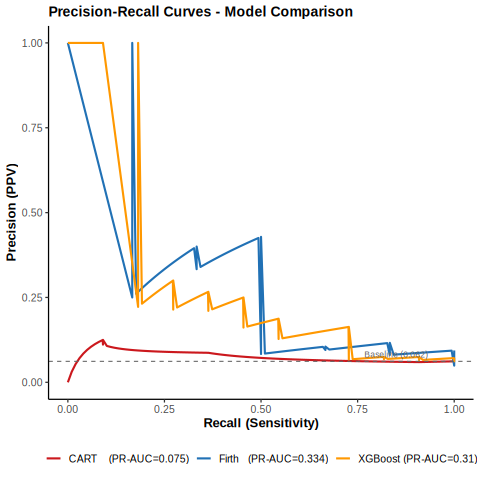

In [121]:
%%R
library(PRROC)
library(dplyr)

#  Recompute PR curves WITH curve=TRUE

# XGBoost
pr_xgb_c <- PRROC::pr.curve(scores.class0 = xgb_pred_df$LOS,
                              weights.class0 = test_labels,
                              curve = TRUE)

# Firth (hardcoded predictions already computed)
pr_firth_c <- PRROC::pr.curve(scores.class0 = firth_prob_test,
                                weights.class0 = test_df_firth$LOS_num,
                                curve = TRUE)

# CART
pr_cart_c <- PRROC::pr.curve(scores.class0 = cart_pred,
                               weights.class0 = cart_labels,
                               curve = TRUE)

# Build combined dataframe
pr_to_df <- function(pr_obj, model_name) {
  data.frame(
    Recall    = pr_obj$curve[, 1],
    Precision = pr_obj$curve[, 2],
    Model     = model_name
  )
}

pr_df <- bind_rows(
  pr_to_df(pr_xgb_c,   paste0("XGBoost (PR-AUC=", round(pr_xgb_c$auc.integral,  3), ")")),
  pr_to_df(pr_firth_c, paste0("Firth   (PR-AUC=", round(pr_firth_c$auc.integral, 3), ")")),
  pr_to_df(pr_cart_c,  paste0("CART    (PR-AUC=", round(pr_cart_c$auc.integral,  3), ")"))
)

p_pr <- ggplot(pr_df, aes(x = Recall, y = Precision, colour = Model)) +
  geom_line(linewidth = 1) +
  geom_hline(yintercept = mean(test_labels), linetype = "dashed",
             colour = COL_GREY) +
  annotate("text", x = 0.85, y = mean(test_labels) + 0.02,
           label = paste0("Baseline (", round(mean(test_labels), 3), ")"),
           colour = COL_GREY, size = 3) +
  scale_colour_manual(values = c(COL_RED, COL_BLUE, "#FF9800")) +
  scale_x_continuous(limits = c(0, 1)) +
  scale_y_continuous(limits = c(0, 1)) +
  labs(title = "Precision-Recall Curves - Model Comparison",
       x = "Recall (Sensitivity)",
       y = "Precision (PPV)",
       colour = NULL) +
  theme_los()

SaveFig(p_pr, "PR_Comparison")
print(p_pr)

In [124]:
%%R
library(gt)

los_def_table <- data.frame(
  Indicator = c("C-sections",
                "Navel treatments",
                "Large-calf remarks",
                "LOS-positive*"),
  ET_calves    = c("2", "66", "18", "82*"),
  NonET_calves = c("0", "9",  "3",  "12")
)

colnames(los_def_table) <- c("Indicator",
                              "Embryo Transfer calves (n=3,323)",
                              "Non-Embryo Transfer calves (n=2,899)")

print(los_def_table)

write.csv(los_def_table,
          file.path(FigDir, "Table1_LOSDefinition.csv"),
          row.names = FALSE)
cat("Saved: Table1_LOSDefinition.csv\n")

           Indicator Embryo Transfer calves (n=3,323)
1         C-sections                                2
2   Navel treatments                               66
3 Large-calf remarks                               18
4      LOS-positive*                              82*
  Non-Embryo Transfer calves (n=2,899)
1                                    0
2                                    9
3                                    3
4                                   12
Saved: Table1_LOSDefinition.csv


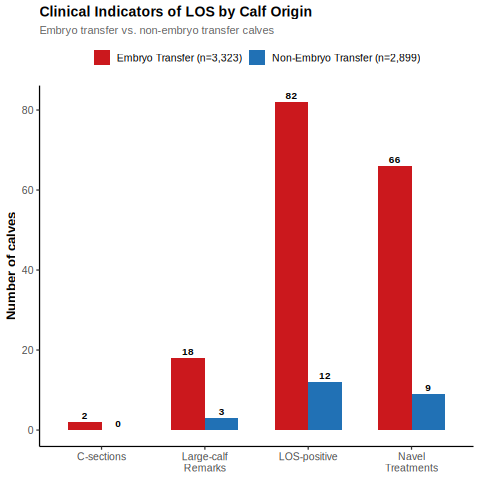

In [125]:
%%R
los_viz <- data.frame(
  Indicator = rep(c("C-sections", "Navel\nTreatments",
                    "Large-calf\nRemarks", "LOS-positive"), 2),
  Group     = rep(c("Embryo Transfer (n=3,323)",
                    "Non-Embryo Transfer (n=2,899)"), each = 4),
  Count     = c(2, 66, 18, 82,   # ET
                0,  9,  3, 12)   # Non-ET
)

p_los_def <- ggplot(los_viz, aes(x = Indicator, y = Count, fill = Group)) +
  geom_col(position = "dodge", width = 0.65) +
  geom_text(aes(label = Count),
            position = position_dodge(width = 0.65),
            vjust = -0.5, size = 3.5, fontface = "bold") +
  scale_fill_manual(values = c(COL_RED, COL_BLUE), name = NULL) +
  labs(title    = "Clinical Indicators of LOS by Calf Origin",
       subtitle = "Embryo transfer vs. non-embryo transfer calves",
       x = NULL, y = "Number of calves") +
  theme_los() +
  theme(legend.position = "top")

SaveFig(p_los_def, "Figure_LOSDefinition")
print(p_los_def)